# Лабораторная работа № 4
## Снижение размерности признакового пространства методами обучения многообразию
### Вариант 7

Набор данных: Body Performance. Целевой признак `class` - класс физической подготовленности (A - лучший, D - худший).

Выполнили: Корепанов Дмитрий Михайлович, группа 932302; Сальников Никита Сергеевич, группа 932301.

## Цель работы

Получить практические навыки снижения размерности признакового пространства методами обучения многообразию, визуализации многомерных данных в двумерном и трехмерном пространствах, анализа структуры классов, кластеризации полученных представлений и построения классификаторов на двумерных вложениях.

## Задание

1. Выбрать набор данных из лабораторной работы № 1, предназначенный для решения задачи многоклассовой классификации, и отобрать не менее шести непрерывных числовых признаков.
2. Выполнить предварительную обработку данных: проверить пропуски и выбросы, привести признаки к сопоставимому масштабу, сформировать матрицу признаков и вектор классов.
3. Преобразовать исходное признаковое пространство в 2D и 3D с помощью методов MDS, Isomap, LLE, t-SNE и UMAP.
4. Визуализировать полученные вложения, используя единый цвет для объектов одного исходного класса, и сравнить степень разделимости классов.
5. Выполнить кластеризацию координат каждого вложения алгоритмом K-means при числе кластеров от 3 до 6 и проанализировать состав кластеров.
6. Для каждого двумерного вложения обучить классификаторы Decision Tree и Random Forest, визуализировать границы решений и сравнить качество моделей.
7. Сопоставить методы снижения размерности по визуальному качеству, сохранению структуры данных, результатам кластеризации и классификации.
8. Сформулировать выводы о преимуществах, ограничениях и применимости рассмотренных методов.

## Настройка

Первая ячейка задает общие пути, зерно и оформление графиков. Все эксперименты используют одно значение `SEED`, поэтому результаты воспроизводимы.

Keras в этой работе не нужен: методы снижения размерности, кластеризация и классификаторы берутся из scikit-learn и umap-learn.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
np.random.seed(SEED)

# Ноутбук лежит в labs/lab4/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты: методы обучения многообразию, кластеризация, деревья решений и вспомогательные функции. Здесь же собраны все константы эксперимента, чтобы условия были одинаковыми для всех методов.

In [2]:
import time

import joblib
import seaborn as sns
import umap
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 - нужен для трехмерных осей
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.manifold import MDS, TSNE, Isomap, LocallyLinearEmbedding, trustworthiness
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    confusion_matrix,
    normalized_mutual_info_score,
    precision_recall_fscore_support,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_FILE = DATA_DIR / "body-performance" / "bodyPerformance.csv"
TARGET = "class"

# Классы упорядочены от лучшего к худшему, кодируем их числами 0-3
CLASS_NAMES = ["A", "B", "C", "D"]
NUMBER_OF_CLASSES = len(CLASS_NAMES)
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

METHODS = ["MDS", "Isomap", "LLE", "t-SNE", "UMAP"]
METHOD_SLUGS = {"MDS": "mds", "Isomap": "isomap", "LLE": "lle", "t-SNE": "tsne", "UMAP": "umap"}

# Отбираем только непрерывные числовые признаки. Пол, идентификаторы и целевой
# признак в матрицу X не входят
FEATURE_COLUMNS = [
    "age",
    "height_cm",
    "weight_kg",
    "body fat_%",
    "diastolic",
    "systolic",
    "gripForce",
    "sit and bend forward_cm",
    "sit-ups counts",
    "broad jump_cm",
]

# MDS, Isomap и LLE строят матрицу попарных расстояний размера n x n.
# При 13 392 объектах это около 1,4 ГБ и очень долгие вычисления, поэтому
# берем стратифицированную подвыборку. Все методы работают на одних и тех же объектах
SUBSAMPLE_SIZE = 5000

# Доля тестовой части в задаче классификации на двумерных вложениях
TEST_SIZE = 0.30

# Число соседей при оценке сохранения структуры
TRUSTWORTHINESS_NEIGHBORS = 5

# Если конфигурации различаются по trustworthiness меньше этого значения,
# считаем разницу шумом и оставляем более простую конфигурацию
CONFIG_TOLERANCE = 0.005

# Диапазон числа кластеров и K для рисунков с кластерами
K_RANGE = [3, 4, 5, 6]
CLUSTER_PLOT_K = 4

# Кросс-валидация для подбора гиперпараметров классификаторов
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## Описание набора данных

**Источник:** Body Performance Data, Kaggle (https://www.kaggle.com/datasets/kukuroo3/body-performance-data). Первичные данные: Корейский фонд развития спорта (Korea Sports Promotion Foundation). Файл: `bodyPerformance.csv`.

**Перевод описания набора:**

Данные, подтверждающие уровень физической подготовки: возраст и результаты выполнения физических упражнений. Размер данных: 13 393 записи, 12 столбцов. Исходные данные прошли постобработку и фильтрацию. Столбец класса стратифицирован, то есть классы A, B, C и D представлены почти поровну. Класс A - лучший.

**Что такое одна запись:** один человек, прошедший тест физической подготовленности. Измерены возраст, пол, рост, вес, доля жира, давление, сила хвата, гибкость, число подъемов туловища и длина прыжка.

**Что предсказываем:** класс физической подготовленности A, B, C или D по измеренным показателям.

**Зачем:** понять, какие измеряемые показатели связаны с уровнем подготовленности, и получить наглядное представление о структуре групп людей.

**Поля набора:**

| Поле | Содержание | Единицы | Диапазон по данным |
|---|---|---|---|
| `age` | Возраст | лет | 21-64 |
| `gender` | Пол: F женский, M мужской | - | 2 значения |
| `height_cm` | Рост | см | 125,0-193,8 |
| `weight_kg` | Вес | кг | 26,3-138,1 |
| `body fat_%` | Доля жира в организме | % | 3,0-78,4 |
| `diastolic` | Диастолическое артериальное давление | мм рт. ст. | 0-156,2, нули ошибочны |
| `systolic` | Систолическое артериальное давление | мм рт. ст. | 0-201, нули ошибочны |
| `gripForce` | Сила хвата | кг | 0-70,5, нули ошибочны |
| `sit and bend forward_cm` | Наклон вперед сидя | см | -25,0-213,0, 213 ошибочно |
| `sit-ups counts` | Количество подъемов туловища | раз | 0-80 |
| `broad jump_cm` | Прыжок в длину с места | см | 0-303, нули ошибочны |
| `class` | Класс физической подготовленности | A, B, C, D | 4 класса |

В работе используются 10 непрерывных признаков. `gender` - категориальный код, `class` - целевая переменная, поэтому они в матрицу признаков не входят.

Загружаем файл. Если данных нет, ноутбук сразу сообщает, что и откуда скачать.

In [3]:
# labs/data нет в git, поэтому каждый участник скачивает набор сам
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Не найден файл {DATA_FILE}. Скачайте набор "
        "https://www.kaggle.com/datasets/kukuroo3/body-performance-data "
        "и положите его в папку labs/data/body-performance"
    )

raw_data = pd.read_csv(DATA_FILE, encoding="utf-8")
print("Размер набора (записей, столбцов):", raw_data.shape)
raw_data.head(10)

Размер набора (записей, столбцов): (13393, 12)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B
5,36,F,165.4,55.40,22.0,64.0,119.0,23.8,21.0,27.0,153.0,B
6,42,F,164.5,63.70,32.2,72.0,135.0,22.7,0.8,18.0,146.0,D
7,33,M,174.9,77.20,36.9,84.0,137.0,45.9,12.3,42.0,234.0,B
8,54,M,166.8,67.50,27.6,85.0,165.0,40.4,18.6,34.0,148.0,C
9,28,M,185.0,84.60,14.4,81.0,156.0,57.9,12.1,55.0,213.0,B


## Анализ данных

### Типы полей и описательная статистика

Смотрим типы столбцов, диапазоны значений и пропуски. Строковые поля `gender` и `class` нужно будет закодировать, но в матрицу признаков они не войдут.

In [4]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  int64  
 1   gender                   13393 non-null  str    
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  str    
dtypes: float64(9), int64(1), str(2)
memory usage: 1.2 MB


In [5]:
raw_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,13393.0,36.775,13.626,21.0,25.0,32.0,48.0,64.0
height_cm,13393.0,168.560,8.427,125.0,162.4,169.2,174.8,193.8
weight_kg,13393.0,67.447,11.950,26.3,58.2,67.4,75.3,138.1
body fat_%,13393.0,23.240,7.257,3.0,18.0,22.8,28.0,78.4
diastolic,13393.0,78.797,10.742,0.0,71.0,79.0,86.0,156.2
systolic,13393.0,130.235,14.714,0.0,120.0,130.0,141.0,201.0
gripForce,13393.0,36.964,10.625,0.0,27.5,37.9,45.2,70.5
sit and bend forward_cm,13393.0,15.209,8.457,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13393.0,39.771,14.277,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13393.0,190.130,39.868,0.0,162.0,193.0,221.0,303.0


In [6]:
print("Пропусков всего:", raw_data.isna().sum().sum())
print("Полных дубликатов:", raw_data.duplicated().sum())
print("Значения gender:", raw_data["gender"].value_counts().to_dict())

Пропусков всего: 0
Полных дубликатов: 1
Значения gender: {'M': 8467, 'F': 4926}


**Результат:** в наборе 13 393 записи и 12 столбцов. Пропусков нет, полный дубликат один. Признак `age` целочисленный, остальные девять признаков вещественные, `gender` и `class` - строковые. Пол: 8 467 мужчин и 4 926 женщин, то есть мужчин почти в 1,7 раза больше.

Диапазоны выглядят правдоподобно: возраст 21-64 года (в среднем 36,8), рост 125,0-193,8 см, вес 26,3-138,1 кг, доля жира 3,0-78,4 %, наклон вперед от -25,0 до 213,0 см, подъемы туловища 0-80, прыжок 0-303 см. Одновременно видны подозрительные минимумы: диастолическое и систолическое давление 0, сила хвата 0, прыжок 0. Ноль в давлении и прыжке физически невозможен, а наклон 213 см явно ошибка ввода. Эти значения разбираются в следующем разделе.

Вывод: по пропускам данные чистые, но требуют проверки физических границ и удаления одного дубликата до разбиения.

### Баланс классов

Проверяем, одинаково ли представлены классы. От этого зависит, можно ли использовать Accuracy как основную метрику и нужны ли веса классов.

class
A    3348
B    3347
C    3349
D    3349
Доли классов: {'A': 0.25, 'B': 0.2499, 'C': 0.2501, 'D': 0.2501}


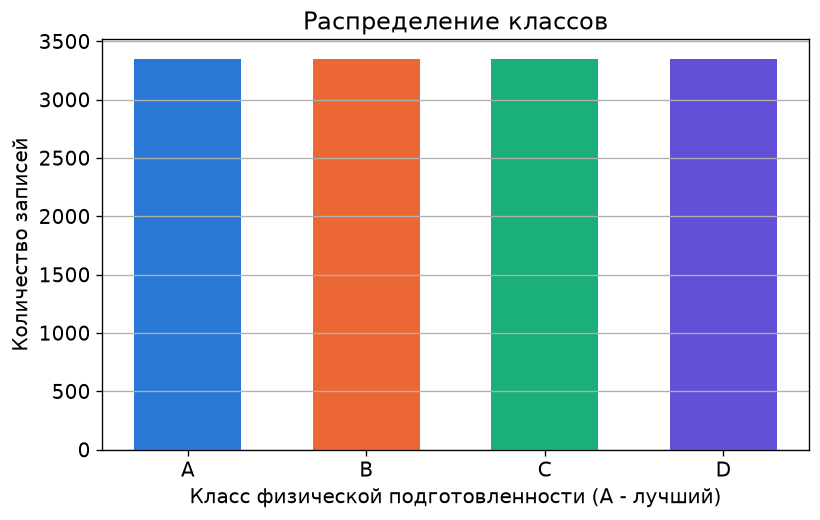

In [7]:
class_counts = raw_data[TARGET].value_counts().reindex(CLASS_NAMES)
print(class_counts.to_string())
print("Доли классов:", (class_counts / len(raw_data)).round(4).to_dict())

figure, axis = plt.subplots(figsize=(7, 4.5))
axis.bar(CLASS_NAMES, class_counts.values, color=CLASS_COLORS, width=0.6)
axis.set_xlabel("Класс физической подготовленности (A - лучший)")
axis.set_ylabel("Количество записей")
axis.set_title("Распределение классов")
axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "lab4-class-balance.png")
plt.show()

**Результат:** классы почти равны: A - 3 348, B - 3 347, C - 3 349, D - 3 349 записей, доли 0,2500, 0,2499, 0,2501 и 0,2501. Дисбаланса нет, поэтому Accuracy можно использовать как основную метрику, а веса классов не нужны. Случайное угадывание дает Accuracy около 0,25 и macro F1 около 0,10; это уровень, с которым сравниваются все модели.

### Выбросы и невозможные значения

Правило 1,5 IQR показывает необычные значения, но не отличает ошибку от редкого факта. Поэтому дополнительно проверяем физические правила: давление, сила хвата или прыжок не могут быть равны нулю или лежать вне разумных границ.

,Признак,Нижняя граница,Верхняя граница,Записей вне границ,Минимум,Максимум
0,age,-9.50,82.50,0,21.0,64.0
1,height_cm,143.80,193.40,10,125.0,193.8
2,weight_kg,32.55,100.95,83,26.3,138.1
3,body fat_%,3.00,43.00,77,3.0,78.4
4,diastolic,48.50,108.50,54,0.0,156.2
5,systolic,88.50,172.50,29,0.0,201.0
6,gripForce,0.95,71.75,3,0.0,70.5
7,sit and bend forward_cm,-3.80,35.40,409,-25.0,213.0
8,sit-ups counts,0.00,80.00,0,0.0,80.0
9,broad jump_cm,73.50,309.50,57,0.0,303.0


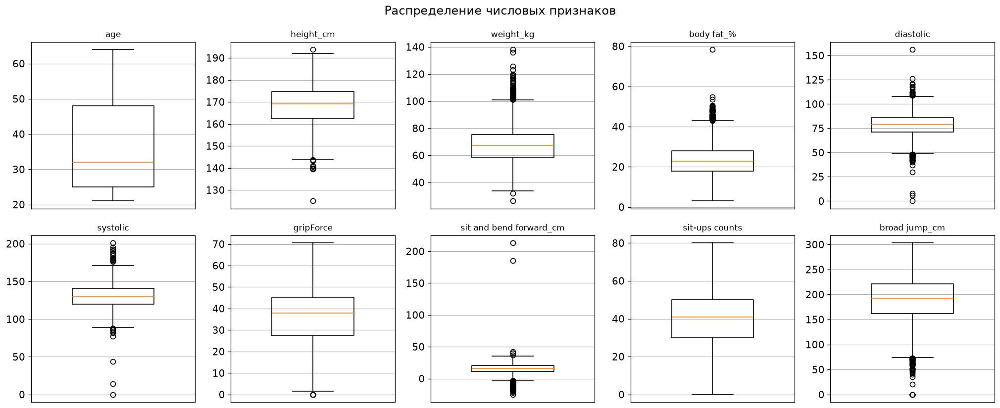

In [8]:
numeric_columns = FEATURE_COLUMNS

# Правило 1,5 IQR считаем только для описания данных
outlier_rows = []
for column in numeric_columns:
    first_quartile, third_quartile = raw_data[column].quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    lower_bound = first_quartile - 1.5 * iqr
    upper_bound = third_quartile + 1.5 * iqr
    outside_count = int(((raw_data[column] < lower_bound) | (raw_data[column] > upper_bound)).sum())
    outlier_rows.append({
        "Признак": column,
        "Нижняя граница": round(lower_bound, 2),
        "Верхняя граница": round(upper_bound, 2),
        "Записей вне границ": outside_count,
        "Минимум": raw_data[column].min(),
        "Максимум": raw_data[column].max(),
    })
display(pd.DataFrame(outlier_rows))

figure, axes = plt.subplots(2, 5, figsize=(17, 7))
for axis, column in zip(axes.ravel(), numeric_columns):
    axis.boxplot(raw_data[column], widths=0.5)
    axis.set_title(column, fontsize=10)
    axis.set_xticks([])
figure.suptitle("Распределение числовых признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "lab4-outliers.png")
plt.show()

In [9]:
def impossible_value_masks(frame):
    """Возвращает словарь: признак -> маска записей с физически невозможным значением.

    Правила зафиксированы заранее и не используют статистику выборки, поэтому
    их можно применять к любой части данных без риска утечки.
    """
    return {
        "diastolic": (frame["diastolic"] < 40) | (frame["diastolic"] >= frame["systolic"]),
        "systolic": (frame["systolic"] < 70) | (frame["diastolic"] >= frame["systolic"]),
        "gripForce": frame["gripForce"] == 0,
        "broad jump_cm": frame["broad jump_cm"] == 0,
        "sit and bend forward_cm": (frame["sit and bend forward_cm"] > 50)
        | (frame["sit and bend forward_cm"] < -20),
    }


for column, mask in impossible_value_masks(raw_data).items():
    print(f"{column}: {int(mask.sum())} записей с невозможным значением")
print("Записей с sit-ups counts = 0:", int((raw_data["sit-ups counts"] == 0).sum()),
      "(оставляем: человек мог не выполнить ни одного подъема)")

diastolic: 9 записей с невозможным значением
systolic: 5 записей с невозможным значением
gripForce: 3 записей с невозможным значением
broad jump_cm: 10 записей с невозможным значением
sit and bend forward_cm: 4 записей с невозможным значением
Записей с sit-ups counts = 0: 125 (оставляем: человек мог не выполнить ни одного подъема)


**Результат:** правило 1,5 IQR отмечает больше всего значений у наклона (409), веса (83), доли жира (77), прыжка (57), диастолического (54) и систолического (29) давления. Большая часть этих записей - реальные крайние случаи, а не ошибки, поэтому удалять их нельзя: иначе выборка потеряет людей с необычным телосложением.

Физические правила нашли 31 невозможное значение: диастолическое давление - 9, систолическое - 5, сила хвата - 3, прыжок - 10, наклон - 4. Записи не удалены: значения заменены на пропуски и заполнены медианой, обученной на train. Ноль в подъемах туловища (125 записей) оставлен, потому что человек мог действительно не выполнить ни одного подъема.

### Матрица корреляций и связь признаков с классом

Для корреляции временно кодируем класс порядковым числом A=0 ... D=3. Это только для анализа, в обучении участвует исходная метка.

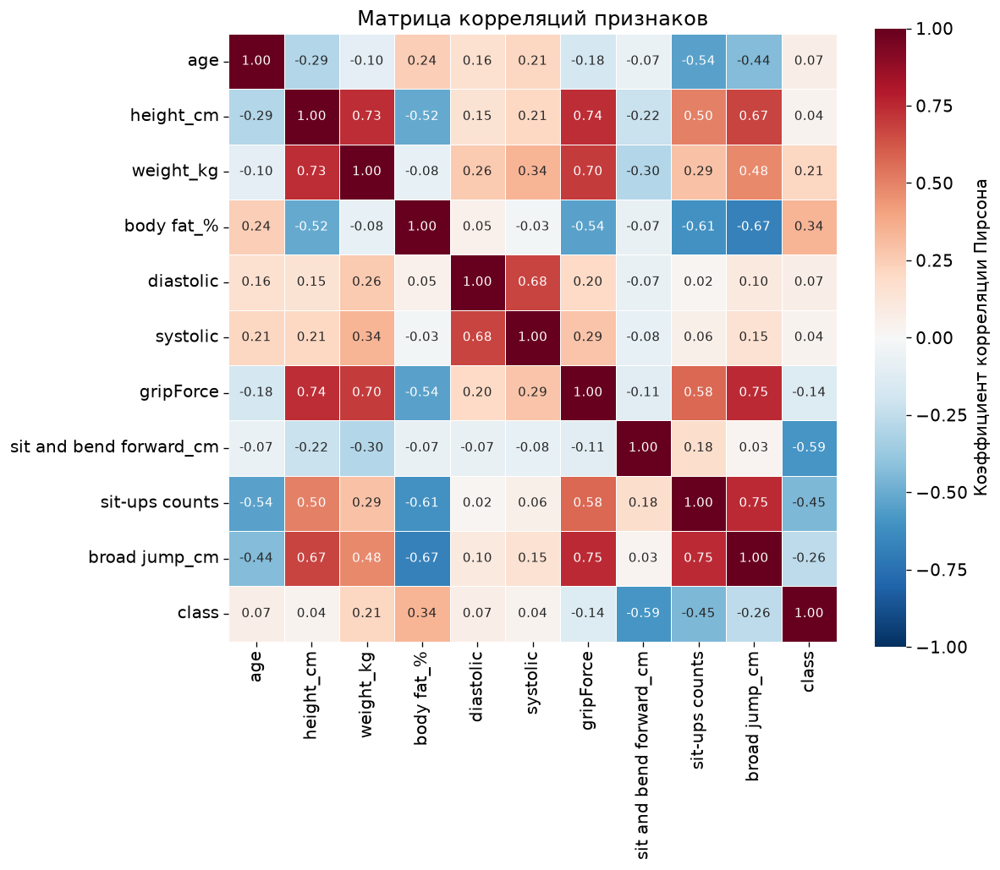

sit and bend forward_cm   -0.588
sit-ups counts            -0.453
body fat_%                 0.342
broad jump_cm             -0.262
weight_kg                  0.214
gripForce                 -0.136
diastolic                  0.067
age                        0.066
height_cm                  0.038
systolic                   0.035


In [10]:
correlation_frame = raw_data.copy()
correlation_frame[TARGET] = correlation_frame[TARGET].map({name: code for code, name in enumerate(CLASS_NAMES)})
correlation_matrix = correlation_frame[numeric_columns + [TARGET]].corr()

figure, axis = plt.subplots(figsize=(10, 8.5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 9},
            cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=axis)
# Сетку осей отключаем: на тепловой карте ее линии перечеркивают ячейки
axis.grid(False)
axis.set_title("Матрица корреляций признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "lab4-correlation.png")
plt.show()

print(correlation_matrix[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).round(3).to_string())

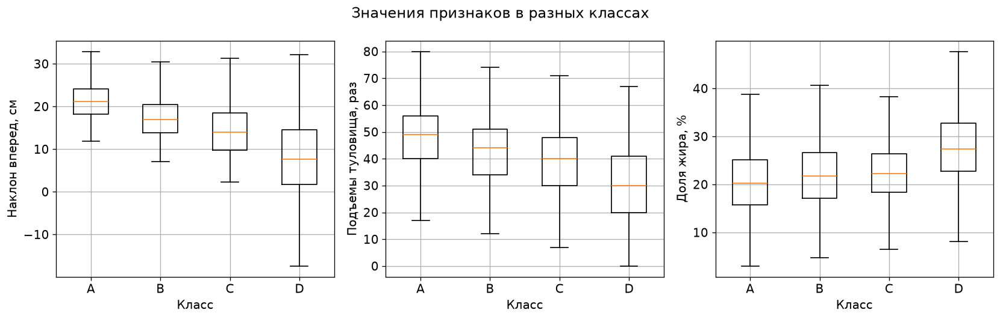

In [11]:
# Распределение трех самых связанных с классом признаков по классам
figure, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for axis, column, label in zip(
    axes,
    ["sit and bend forward_cm", "sit-ups counts", "body fat_%"],
    ["Наклон вперед, см", "Подъемы туловища, раз", "Доля жира, %"],
):
    class_values = [raw_data.loc[raw_data[TARGET] == name, column] for name in CLASS_NAMES]
    axis.boxplot(class_values, tick_labels=CLASS_NAMES, widths=0.5, showfliers=False)
    axis.set_xlabel("Класс")
    axis.set_ylabel(label)
figure.suptitle("Значения признаков в разных классах")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "lab4-features-by-class.png")
plt.show()

**Результат:** с порядковым номером класса сильнее всего связаны наклон вперед (-0,588), число подъемов туловища (-0,453) и доля жира (0,342); заметны также прыжок (-0,262) и вес (0,214). Давление, возраст и рост почти не различают классы (модуль коэффициента не больше 0,07), сила хвата связана слабо (-0,136). Связь умеренная, одного признака для уверенной классификации недостаточно.

Внутри признаков есть сильные корреляции: рост и вес (0,73), подъемы туловища и прыжок (0,75), доля жира с подъемами (-0,61), прыжком (-0,67) и ростом (-0,52), возраст с подъемами (-0,54), диастолическое и систолическое давление (0,68). Признаки частично дублируют друг друга, поэтому снижение размерности имеет смысл: часть осей отражает общий фактор телосложения и выносливости.

На графике распределений по классам видны сдвиги медиан: у наклона медиана падает с 21,1 см у A до 7,7 см у D, у подъемов туловища - с 49 до 30, у доли жира растет с 20,2 % до 27,4 %. Но диапазоны сильно перекрываются, поэтому ожидаются ошибки между соседними классами.

## Подготовка данных

Порядок действий:

1. Удаляем полный дубликат до разбиения, чтобы одинаковая запись не попала в train и test одновременно.
2. Физически невозможные значения заменяем на пропуски по правилам, которые не зависят от выборки.
3. Формируем стратифицированную подвыборку 5 000 объектов. Причина: MDS, Isomap и LLE строят матрицу попарных расстояний размера n x n, на 13 392 объектах это около 1,4 ГБ памяти и десятки минут на каждый запуск. Все пять методов работают на одних и тех же объектах, доли классов сохраняются.
4. Делим данные 70 / 30 со стратификацией, как требует задание для классификации на двумерных вложениях.
5. Импутацию медианой и стандартизацию обучаем только на train и применяем к остальным частям.

In [12]:
# Полный дубликат удаляем до разбиения
data = raw_data.drop_duplicates().reset_index(drop=True)
print("Записей после удаления дубликатов:", len(data))

# Невозможные значения заменяем на пропуски. Сначала вычисляем все маски,
# потом меняем значения: правила для diastolic и systolic зависят друг от друга
prepared = data.copy()
masks = impossible_value_masks(prepared)
for column, mask in masks.items():
    prepared.loc[mask, column] = np.nan

print("Пропусков после замены:")
print(prepared[FEATURE_COLUMNS].isna().sum()[prepared[FEATURE_COLUMNS].isna().sum() > 0].to_string())

Записей после удаления дубликатов: 13392
Пропусков после замены:
diastolic                   9
systolic                    5
gripForce                   3
sit and bend forward_cm     4
broad jump_cm              10


In [13]:
X_all = prepared[FEATURE_COLUMNS].astype(float)
y_all = prepared[TARGET].map({name: code for code, name in enumerate(CLASS_NAMES)}).to_numpy()

# Стратифицированная подвыборка: сохраняем доли классов
subsample_indices, _ = train_test_split(
    np.arange(len(X_all)), train_size=SUBSAMPLE_SIZE, stratify=y_all, random_state=SEED
)
X = X_all.iloc[subsample_indices].reset_index(drop=True)
y = y_all[subsample_indices]

subsample_summary = pd.DataFrame({
    "Выборка": ["Полный набор", "Подвыборка"],
    "Записей": [len(X_all), len(X)],
    **{f"Класс {name}": [int((y_all == index).sum()), int((y == index).sum())]
       for index, name in enumerate(CLASS_NAMES)},
})
subsample_summary["Доля класса A, %"] = [round(100 * (y_all == 0).mean(), 2), round(100 * (y == 0).mean(), 2)]
display(subsample_summary)

,Выборка,Записей,Класс A,Класс B,Класс C,Класс D,"Доля класса A, %"
0,Полный набор,13392,3347,3347,3349,3349,24.99
1,Подвыборка,5000,1250,1250,1250,1250,25.00


### Разбиение на обучающую и тестовую части

Задание разрешает пропорцию 70 / 30 со стратификацией. Разбиение выполняется до обучения предобработки: медиана и параметры масштабирования считаются только по train.

In [14]:
train_idx, test_idx = train_test_split(
    np.arange(len(X)), test_size=TEST_SIZE, stratify=y, random_state=SEED
)

X_train_raw = X.iloc[train_idx]
X_test_raw = X.iloc[test_idx]

# Импутация и стандартизация обучаются только на train, затем применяются ко всем частям
preprocessor = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
# X_scaled нужен для описательной части: визуализации и кластеризации всех объектов
X_scaled = preprocessor.transform(X)

joblib.dump(preprocessor, MODELS_DIR / "lab4-preprocessor.joblib")

split_rows = {}
for split_name, indices in [("train", train_idx), ("test", test_idx)]:
    counts = np.bincount(y[indices], minlength=NUMBER_OF_CLASSES)
    split_rows[split_name] = {
        "Записей": len(indices),
        **{f"Класс {name}": int(count) for name, count in zip(CLASS_NAMES, counts)},
    }
split_summary = pd.DataFrame(split_rows).T
split_summary.to_csv(RESULTS_DIR / "lab4-split.csv", encoding="utf-8")

print("Размеры матриц: train", X_train.shape, "test", X_test.shape, "все объекты", X_scaled.shape)
print("Пропусков после импутации:", int(np.isnan(X_scaled).sum()))
print("Среднее по train после масштабирования:", np.round(X_train.mean(axis=0), 4))
print("Стандартное отклонение по train:", np.round(X_train.std(axis=0), 4))
display(split_summary)

Размеры матриц: train (3500, 10) test (1500, 10) все объекты (5000, 10)
Пропусков после импутации: 0
Среднее по train после масштабирования: [-0.  0.  0.  0. -0. -0. -0. -0. -0. -0.]
Стандартное отклонение по train: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,Записей,Класс A,Класс B,Класс C,Класс D
train,3500,875,875,875,875
test,1500,375,375,375,375


### Описательная статистика выбранных признаков

Таблица средних, стандартных отклонений, минимума и максимума по десяти непрерывным признакам. Сохраняем ее в `results`, чтобы числа в отчете не расходились с ноутбуком.

In [15]:
descriptive_stats = prepared[FEATURE_COLUMNS].agg(["mean", "std", "min", "max"]).T.round(3)
descriptive_stats.index.name = "Признак"
descriptive_stats.columns = ["Среднее", "Стандартное отклонение", "Минимум", "Максимум"]
descriptive_stats.to_csv(RESULTS_DIR / "lab4-descriptive.csv", encoding="utf-8")
display(descriptive_stats)

,Среднее,Стандартное отклонение,Минимум,Максимум
Признак,,,,
age,36.776,13.626,21.0,64.0
height_cm,168.561,8.426,125.0,193.8
weight_kg,67.449,11.949,26.3,138.1
body fat_%,23.240,7.257,3.0,78.4
diastolic,78.817,10.647,40.0,126.0
systolic,130.268,14.611,77.0,201.0
gripForce,36.973,10.612,1.6,70.5
sit and bend forward_cm,15.187,8.139,-20.0,42.0
sit-ups counts,39.770,14.277,0.0,80.0


**Результат:** после удаления дубликата осталось 13 392 записи. Замена невозможных значений дала 31 пропуск: 9 в диастолическом давлении, 5 в систолическом, 3 в силе хвата, 4 в наклоне и 10 в прыжке. Строки сохранены.

Стратифицированная подвыборка содержит 5 000 объектов ровно по 1 250 на класс. Разбиение 70 / 30 дало 3 500 обучающих и 1 500 тестовых объектов, в каждой части по 875 и по 375 объектов каждого класса. Доли классов в train и test совпадают с исходными.

Импутация медианой и стандартизация обучены только на train. После преобразования среднее по train равно нулю, стандартное отклонение - единице; тест масштабирован теми же параметрами, поэтому утечки нет. Предобработка сохранена в `models/lab4-preprocessor.joblib`.

## Базовая модель

Метрики задания считаются одной функцией для всех классификаторов. Для каждого класса считаем Precision, Recall и F1, затем средние:

$$ macro = \frac{1}{K}\sum_{k=1}^{K} m_k, \quad weighted = \sum_{k=1}^{K} \frac{n_k}{n} m_k $$

Базовая модель `Dummy` всегда называет самый частый класс. При четырех равных классах ее Accuracy около 0,25, это уровень случайного угадывания.

In [16]:
def classification_metrics(evaluation, method, model_name, y_true, y_pred, params=""):
    """Считает метрики задания и возвращает одну строку итоговой таблицы."""
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    return {
        "Оценка": evaluation,
        "Метод": method,
        "Модель": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision macro": round(precision_macro, 4),
        "Recall macro": round(recall_macro, 4),
        "F1 macro": round(f1_macro, 4),
        "Precision weighted": round(precision_weighted, 4),
        "Recall weighted": round(recall_weighted, 4),
        "F1 weighted": round(f1_weighted, 4),
        "Параметры": params,
    }


def per_class_metrics(evaluation, method, model_name, y_true, y_pred):
    """Возвращает Precision, Recall и F1 по каждому классу, а также средние."""
    labels = list(range(NUMBER_OF_CLASSES))
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    macro = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

    rows = []
    for metric_name, values, position in [
        ("Precision", precision, 0),
        ("Recall", recall, 1),
        ("F1-score", f1, 2),
    ]:
        row = {"Оценка": evaluation, "Метод": method, "Модель": model_name, "Метрика": metric_name}
        row.update({f"Класс {name}": round(value, 4) for name, value in zip(CLASS_NAMES, values)})
        row["Macro"] = round(macro[position], 4)
        row["Weighted"] = round(weighted[position], 4)
        rows.append(row)

    support_row = {"Оценка": evaluation, "Метод": method, "Модель": model_name, "Метрика": "Support"}
    support_row.update({f"Класс {name}": int(value) for name, value in zip(CLASS_NAMES, support)})
    support_row["Macro"] = int(support.sum())
    support_row["Weighted"] = int(support.sum())
    rows.append(support_row)
    return rows


def scatter_classes_2d(axis, coordinates, labels, title):
    """Рисует объекты на плоскости, цвет соответствует исходному классу."""
    for class_index, class_name in enumerate(CLASS_NAMES):
        mask = labels == class_index
        axis.scatter(coordinates[mask, 0], coordinates[mask, 1], s=9, alpha=0.7,
                     color=CLASS_COLORS[class_index], label=f"Класс {class_name}", linewidths=0)
    axis.set_title(title)
    axis.set_xlabel("Координата 1 (безразмерная)")
    axis.set_ylabel("Координата 2 (безразмерная)")


def class_legend_handles():
    """Легенда классов для трехмерных графиков."""
    return [Line2D([0], [0], marker="o", linestyle="", color=CLASS_COLORS[index],
                   label=f"Класс {name}", markersize=7)
            for index, name in enumerate(CLASS_NAMES)]

In [17]:
# Базовая модель на исходных десяти признаках: показывает уровень случайного угадывания
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y[train_idx])
dummy_predictions = dummy.predict(X_test)
dummy_row = classification_metrics("Базовая", "-", "Dummy", y[test_idx], dummy_predictions)
dummy_table = pd.DataFrame([dummy_row])
display(dummy_table)

,Оценка,Метод,Модель,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,Параметры
0,Базовая,-,Dummy,0.25,0.0625,0.25,0.1,0.0625,0.25,0.1,


**Результат:** `DummyClassifier` всегда предсказывает класс A и дает Accuracy 0,2500, macro F1 0,1000 и macro Precision 0,0625. Это ожидаемо при четырех равных классах: модель угадывает один класс из четырех, а по остальным трем Precision и F1 равны нулю.

Все содержательные модели ниже сравниваются с этими значениями. Превышение Accuracy 0,25 означает, что вложение действительно несет информацию о классе, а не только о среднем распределении.

## Эксперименты

Все методы получают одну и ту же стандартизированную матрицу `X_scaled`. Параметры и `random_state` зафиксированы. Для каждого метода сравниваем две конфигурации по trustworthiness - доле ближайших соседей в исходном пространстве, которые остались соседями во вложении. Чем ближе значение к 1, тем лучше сохранена локальная структура.

Если разница по trustworthiness меньше 0,005, считаем ее шумом и оставляем более простую конфигурацию.

### 1. MDS: число инициализаций

MDS размещает объекты так, чтобы попарные расстояния на плоскости по возможности совпадали с расстояниями в исходном пространстве. Сравниваем одну и две случайные инициализации. Для MDS дополнительно смотрим нормированный stress: чем он меньше, тем точнее сохранены расстояния.

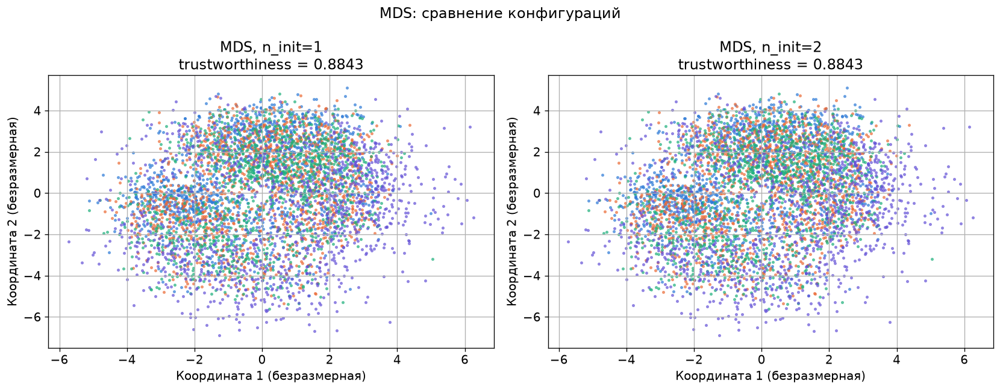

,Метод,Конфигурация,Trustworthiness,"Время, с",Stress
0,MDS,n_init=1,0.8843,146.4,0.2157
1,MDS,n_init=2,0.8843,343.2,0.2157


Выбранная конфигурация MDS: n_init=1


In [18]:
def fit_mds(n_components, n_init):
    """Обучает MDS и возвращает координаты вместе со значением stress."""
    model = MDS(
        n_components=n_components,
        metric_mds=True,
        n_init=n_init,
        init="random",
        max_iter=300,
        normalized_stress=True,
        random_state=SEED,
    )
    coordinates = model.fit_transform(X_scaled)
    return coordinates, {"Stress": round(float(model.stress_), 4)}


def compare_configurations(method, configurations, figure_name):
    """Обучает несколько конфигураций метода, считает trustworthiness и строит графики.

    configurations - список словарей с ключами label, fit и extra.
    fit должен возвращать пару (координаты, словарь дополнительных показателей).
    """
    coordinates_by_label = {}
    rows = []
    for configuration in configurations:
        label = configuration["label"]
        started = time.perf_counter()
        coordinates, extra = configuration["fit"]()
        elapsed = round(time.perf_counter() - started, 1)
        score = trustworthiness(X_scaled, coordinates, n_neighbors=TRUSTWORTHINESS_NEIGHBORS)
        coordinates_by_label[label] = coordinates
        row = {"Метод": method, "Конфигурация": label,
               "Trustworthiness": round(score, 4), "Время, с": elapsed}
        row.update(extra)
        rows.append(row)

    table = pd.DataFrame(rows)

    figure, axes = plt.subplots(1, len(configurations), figsize=(7 * len(configurations), 5.5))
    for axis, configuration in zip(np.atleast_1d(axes), configurations):
        label = configuration["label"]
        scatter_classes_2d(axis, coordinates_by_label[label], y,
                          f"{method}, {label}\ntrustworthiness = {table.loc[table['Конфигурация'] == label, 'Trustworthiness'].iloc[0]:.4f}")
    figure.suptitle(f"{method}: сравнение конфигураций")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / figure_name)
    plt.show()

    display(table)
    return coordinates_by_label, table


def choose_configuration(table, simple_label):
    """Выбирает конфигурацию: лучшую по trustworthiness, если выигрыш больше допуска."""
    best_row = table.loc[table["Trustworthiness"].idxmax()]
    simple_row = table.loc[table["Конфигурация"] == simple_label].iloc[0]
    if best_row["Trustworthiness"] - simple_row["Trustworthiness"] < CONFIG_TOLERANCE:
        return simple_label
    return best_row["Конфигурация"]


mds_coordinates, mds_table = compare_configurations("MDS", [
    {"label": "n_init=1", "fit": lambda: fit_mds(2, 1)},
    {"label": "n_init=2", "fit": lambda: fit_mds(2, 2)},
], "lab4-mds-configs.png")

chosen_configs = {}
chosen_configs["MDS"] = choose_configuration(mds_table, "n_init=1")
print("Выбранная конфигурация MDS:", chosen_configs["MDS"])

**Результат:** обе конфигурации дают одинаковый trustworthiness 0,8843 и stress 0,2157: вторая инициализация не улучшила карту, только увеличила время с 146,4 до 343,2 с. Поэтому выбрана `n_init=1`. В трехмерном варианте trustworthiness растет до 0,9470, а stress падает до 0,1257: в трех координатах удается точнее сохранить исходные расстояния.

Stress 0,2157 в двумерном случае означает заметное искажение глобальных расстояний, что типично для MDS при переходе из десяти измерений в два. Карта пригодна для обзора, но не для точного измерения близости.

### 2. Isomap: число соседей

Isomap строит граф ближайших соседей и приближает геодезические расстояния по этому графу. Малое число соседей может разорвать граф на куски, большое - сгладить структуру. Сравниваем 10 и 30 соседей.

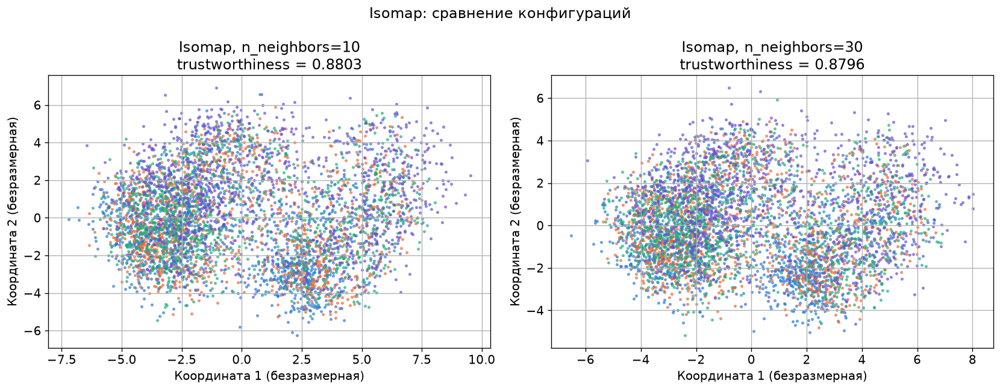

,Метод,Конфигурация,Trustworthiness,"Время, с"
0,Isomap,n_neighbors=10,0.8803,6.2
1,Isomap,n_neighbors=30,0.8796,8.9


Выбранная конфигурация Isomap: n_neighbors=10


In [19]:
def fit_isomap(n_components, n_neighbors):
    """Обучает Isomap и возвращает координаты."""
    model = Isomap(n_components=n_components, n_neighbors=n_neighbors, n_jobs=-1)
    return model.fit_transform(X_scaled), {}


isomap_coordinates, isomap_table = compare_configurations("Isomap", [
    {"label": "n_neighbors=10", "fit": lambda: fit_isomap(2, 10)},
    {"label": "n_neighbors=30", "fit": lambda: fit_isomap(2, 30)},
], "lab4-isomap-configs.png")

chosen_configs["Isomap"] = choose_configuration(isomap_table, "n_neighbors=10")
print("Выбранная конфигурация Isomap:", chosen_configs["Isomap"])

**Результат:** k=10 дает trustworthiness 0,8803 за 6,2 с, k=30 - 0,8796 за 8,9 с. Разница 0,0007 меньше допуска 0,005, поэтому по правилу "при близких значениях выбираем более простую модель" оставлено k=10: меньше соседей, проще граф и быстрее расчет.

Значение 0,8803 близко к MDS (0,8843). Это ожидаемо: на плотном облаке без выраженного многообразия геодезические расстояния мало отличаются от евклидовых. В 3D trustworthiness растет до 0,9433.

### 3. LLE: число соседей

LLE описывает каждый объект линейной комбинацией его ближайших соседей и ищет низкоразмерное представление, в котором эти веса сохраняются. Метод чувствителен к числу соседей и шуму, поэтому проверяем 10 и 30.

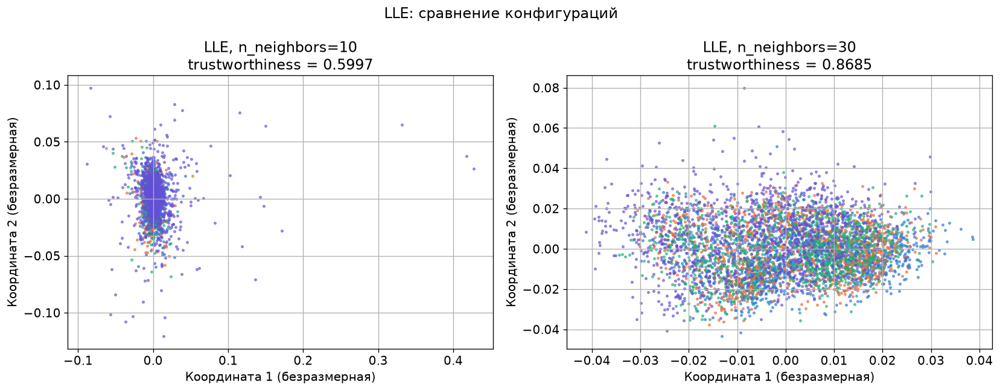

,Метод,Конфигурация,Trustworthiness,"Время, с"
0,LLE,n_neighbors=10,0.5997,3.5
1,LLE,n_neighbors=30,0.8685,6.2


Выбранная конфигурация LLE: n_neighbors=30


In [20]:
def fit_lle(n_components, n_neighbors):
    """Обучает LLE и возвращает координаты."""
    model = LocallyLinearEmbedding(
        n_components=n_components,
        n_neighbors=n_neighbors,
        reg=1e-3,
        random_state=SEED,
        n_jobs=-1,
    )
    return model.fit_transform(X_scaled), {}


lle_coordinates, lle_table = compare_configurations("LLE", [
    {"label": "n_neighbors=10", "fit": lambda: fit_lle(2, 10)},
    {"label": "n_neighbors=30", "fit": lambda: fit_lle(2, 30)},
], "lab4-lle-configs.png")

chosen_configs["LLE"] = choose_configuration(lle_table, "n_neighbors=10")
print("Выбранная конфигурация LLE:", chosen_configs["LLE"])

**Результат:** при k=10 карта схлопывается в узкую полосу и trustworthiness падает до 0,5997, то есть метод сохраняет лишь около 60 % соседства. При k=30 значение растет до 0,8685, время - 6,2 с. Разница 0,2688 многократно больше допуска 0,005, поэтому выбрано k=30.

Даже при удачном k LLE уступает MDS и Isomap (0,8685 против 0,8843 и 0,8803): локальные веса хуже описывают глобальную структуру десятимерного облака. В 3D trustworthiness достигает 0,9259.

### 4. t-SNE: perplexity

t-SNE сохраняет локальные вероятностные сходства между объектами. Perplexity задает эффективное число соседей, которые учитываются для каждого объекта: малые значения подчеркивают мелкие группы, большие - общую структуру. Сравниваем 30 и 50.

Важное ограничение: в scikit-learn 1.9.1 у t-SNE нет метода `transform`, поэтому он не умеет размещать новые объекты. t-SNE используется только для анализа уже имеющегося набора, и все оценки классификации на его карте являются исследовательскими.

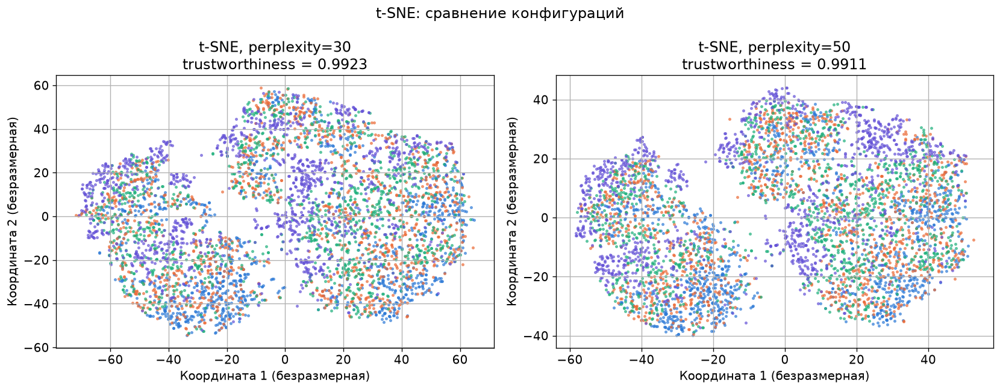

,Метод,Конфигурация,Trustworthiness,"Время, с"
0,t-SNE,perplexity=30,0.9923,12.9
1,t-SNE,perplexity=50,0.9911,15.0


Выбранная конфигурация t-SNE: perplexity=30


In [21]:
def fit_tsne(n_components, perplexity):
    """Обучает t-SNE и возвращает координаты."""
    model = TSNE(
        n_components=n_components,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=SEED,
        n_jobs=-1,
    )
    return model.fit_transform(X_scaled), {}


tsne_coordinates, tsne_table = compare_configurations("t-SNE", [
    {"label": "perplexity=30", "fit": lambda: fit_tsne(2, 30)},
    {"label": "perplexity=50", "fit": lambda: fit_tsne(2, 50)},
], "lab4-tsne-configs.png")

chosen_configs["t-SNE"] = choose_configuration(tsne_table, "perplexity=30")
print("Выбранная конфигурация t-SNE:", chosen_configs["t-SNE"])

**Результат:** perplexity=30 дает trustworthiness 0,9923 за 12,9 с, perplexity=50 - 0,9911 за 15,0 с. Разница 0,0012 меньше допуска 0,005, поэтому оставлено perplexity=30.

t-SNE лучше всех сохраняет соседство: 0,9923 в 2D и 0,9960 в 3D. Это следствие устройства метода: он оптимизирует именно вероятности соседства, а не глобальные расстояния. Поэтому карта хорошо показывает локальные группы, но расстояния между группами и их размеры искажены.

### 5. UMAP: число соседей и минимальное расстояние

UMAP строит граф локальных соседств и оптимизирует низкоразмерное представление, приближая локальную и глобальную структуру. `n_neighbors` задает баланс между локальной и глобальной структурой, `min_dist` - насколько плотно точки могут лежать друг к другу. Сравниваем две конфигурации.

UMAP поддерживает `transform`, поэтому для него можно получить честную оценку на новых объектах.

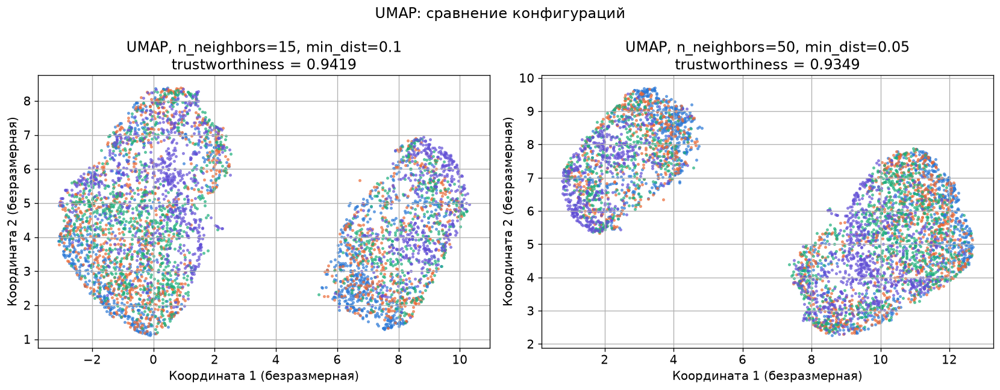

,Метод,Конфигурация,Trustworthiness,"Время, с"
0,UMAP,"n_neighbors=15, min_dist=0.1",0.9419,48.4
1,UMAP,"n_neighbors=50, min_dist=0.05",0.9349,9.6


Выбранная конфигурация UMAP: n_neighbors=15, min_dist=0.1


In [22]:
def fit_umap(n_components, n_neighbors, min_dist):
    """Обучает UMAP и возвращает координаты."""
    model = umap.UMAP(
        n_components=n_components,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        random_state=SEED,
        n_jobs=1,
    )
    return model.fit_transform(X_scaled), {}


umap_coordinates, umap_table = compare_configurations("UMAP", [
    {"label": "n_neighbors=15, min_dist=0.1", "fit": lambda: fit_umap(2, 15, 0.1)},
    {"label": "n_neighbors=50, min_dist=0.05", "fit": lambda: fit_umap(2, 50, 0.05)},
], "lab4-umap-configs.png")

chosen_configs["UMAP"] = choose_configuration(umap_table, "n_neighbors=15, min_dist=0.1")
print("Выбранная конфигурация UMAP:", chosen_configs["UMAP"])

**Результат:** конфигурация n_neighbors=15, min_dist=0,1 дает trustworthiness 0,9419, конфигурация 50 / 0,05 - 0,9349. Разница 0,0070 больше допуска 0,005, поэтому выбрана первая. Время 48,4 с у первого запуска включает компиляцию numba, поэтому повторные запуски быстрее (у второй конфигурации - 9,6 с).

UMAP занимает второе место после t-SNE: 0,9419 в 2D и 0,9774 в 3D. Значение min_dist=0,1 не позволяет точкам слипаться в одну массу, поэтому карта читается лучше, чем при 0,05, где локальные сгустки плотнее, а соседство сохраняется хуже.

### 6. Итоговые двумерные и трехмерные вложения

Для выбранных конфигураций строим трехмерные вложения и сохраняем итоговую таблицу параметров. Все пять методов работают на одних и тех же 5 000 объектах, поэтому карты можно сравнивать между собой.

In [23]:
embeddings_2d = {}
embeddings_3d = {}
embedding_rows = []

# MDS
mds_n_init = 1 if chosen_configs["MDS"] == "n_init=1" else 2
embeddings_2d["MDS"] = mds_coordinates[chosen_configs["MDS"]]
embeddings_3d["MDS"], mds_3d_extra = fit_mds(3, mds_n_init)
embedding_rows.append({
    "Метод": "MDS", "Размерность": 2, "Конфигурация": chosen_configs["MDS"],
    "Параметры": f"n_init={mds_n_init}, init=random",
    "Trustworthiness": float(mds_table.loc[mds_table["Конфигурация"] == chosen_configs["MDS"], "Trustworthiness"].iloc[0]),
    "Stress": float(mds_table.loc[mds_table["Конфигурация"] == chosen_configs["MDS"], "Stress"].iloc[0]),
})
embedding_rows.append({
    "Метод": "MDS", "Размерность": 3, "Конфигурация": chosen_configs["MDS"],
    "Параметры": f"n_init={mds_n_init}, init=random",
    "Trustworthiness": round(float(trustworthiness(X_scaled, embeddings_3d["MDS"], n_neighbors=TRUSTWORTHINESS_NEIGHBORS)), 4),
    "Stress": float(mds_3d_extra["Stress"]),
})

# Isomap
isomap_neighbors = 10 if chosen_configs["Isomap"] == "n_neighbors=10" else 30
embeddings_2d["Isomap"] = isomap_coordinates[chosen_configs["Isomap"]]
embeddings_3d["Isomap"], _ = fit_isomap(3, isomap_neighbors)
for dimensions, coordinates in [(2, embeddings_2d["Isomap"]), (3, embeddings_3d["Isomap"])]:
    embedding_rows.append({
        "Метод": "Isomap", "Размерность": dimensions, "Конфигурация": chosen_configs["Isomap"],
        "Параметры": f"n_neighbors={isomap_neighbors}",
        "Trustworthiness": round(float(trustworthiness(X_scaled, coordinates, n_neighbors=TRUSTWORTHINESS_NEIGHBORS)), 4),
        "Stress": np.nan,
    })

# LLE
lle_neighbors = 10 if chosen_configs["LLE"] == "n_neighbors=10" else 30
embeddings_2d["LLE"] = lle_coordinates[chosen_configs["LLE"]]
embeddings_3d["LLE"], _ = fit_lle(3, lle_neighbors)
for dimensions, coordinates in [(2, embeddings_2d["LLE"]), (3, embeddings_3d["LLE"])]:
    embedding_rows.append({
        "Метод": "LLE", "Размерность": dimensions, "Конфигурация": chosen_configs["LLE"],
        "Параметры": f"n_neighbors={lle_neighbors}, reg=0.001",
        "Trustworthiness": round(float(trustworthiness(X_scaled, coordinates, n_neighbors=TRUSTWORTHINESS_NEIGHBORS)), 4),
        "Stress": np.nan,
    })

# t-SNE
tsne_perplexity = 30 if chosen_configs["t-SNE"] == "perplexity=30" else 50
embeddings_2d["t-SNE"] = tsne_coordinates[chosen_configs["t-SNE"]]
embeddings_3d["t-SNE"], _ = fit_tsne(3, tsne_perplexity)
for dimensions, coordinates in [(2, embeddings_2d["t-SNE"]), (3, embeddings_3d["t-SNE"])]:
    embedding_rows.append({
        "Метод": "t-SNE", "Размерность": dimensions, "Конфигурация": chosen_configs["t-SNE"],
        "Параметры": f"perplexity={tsne_perplexity}, init=pca",
        "Trustworthiness": round(float(trustworthiness(X_scaled, coordinates, n_neighbors=TRUSTWORTHINESS_NEIGHBORS)), 4),
        "Stress": np.nan,
    })

# UMAP
umap_neighbors = 15 if chosen_configs["UMAP"].startswith("n_neighbors=15") else 50
umap_min_dist = 0.1 if umap_neighbors == 15 else 0.05
embeddings_2d["UMAP"] = umap_coordinates[chosen_configs["UMAP"]]
embeddings_3d["UMAP"], _ = fit_umap(3, umap_neighbors, umap_min_dist)
for dimensions, coordinates in [(2, embeddings_2d["UMAP"]), (3, embeddings_3d["UMAP"])]:
    embedding_rows.append({
        "Метод": "UMAP", "Размерность": dimensions, "Конфигурация": chosen_configs["UMAP"],
        "Параметры": f"n_neighbors={umap_neighbors}, min_dist={umap_min_dist}",
        "Trustworthiness": round(float(trustworthiness(X_scaled, coordinates, n_neighbors=TRUSTWORTHINESS_NEIGHBORS)), 4),
        "Stress": np.nan,
    })

embedding_params = pd.DataFrame(embedding_rows)
embedding_params["Trustworthiness"] = embedding_params["Trustworthiness"].round(4)
embedding_params.to_csv(RESULTS_DIR / "lab4-embedding-params.csv", index=False, encoding="utf-8")
display(embedding_params)

,Метод,Размерность,Конфигурация,Параметры,Trustworthiness,Stress
0,MDS,2,n_init=1,"n_init=1, init=random",0.8843,0.2157
1,MDS,3,n_init=1,"n_init=1, init=random",0.9470,0.1257
2,Isomap,2,n_neighbors=10,n_neighbors=10,0.8803,NaN
3,Isomap,3,n_neighbors=10,n_neighbors=10,0.9433,NaN
4,LLE,2,n_neighbors=30,"n_neighbors=30, reg=0.001",0.8685,NaN
5,LLE,3,n_neighbors=30,"n_neighbors=30, reg=0.001",0.9259,NaN
6,t-SNE,2,perplexity=30,"perplexity=30, init=pca",0.9923,NaN
7,t-SNE,3,perplexity=30,"perplexity=30, init=pca",0.9960,NaN
8,UMAP,2,"n_neighbors=15, min_dist=0.1","n_neighbors=15, min_dist=0.1",0.9419,NaN
9,UMAP,3,"n_neighbors=15, min_dist=0.1","n_neighbors=15, min_dist=0.1",0.9774,NaN


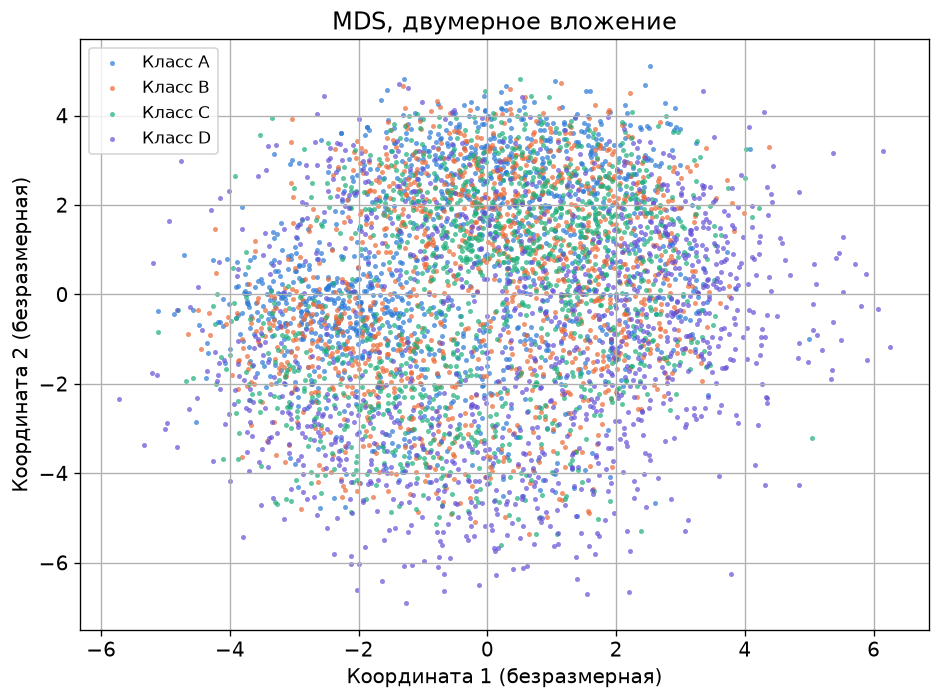

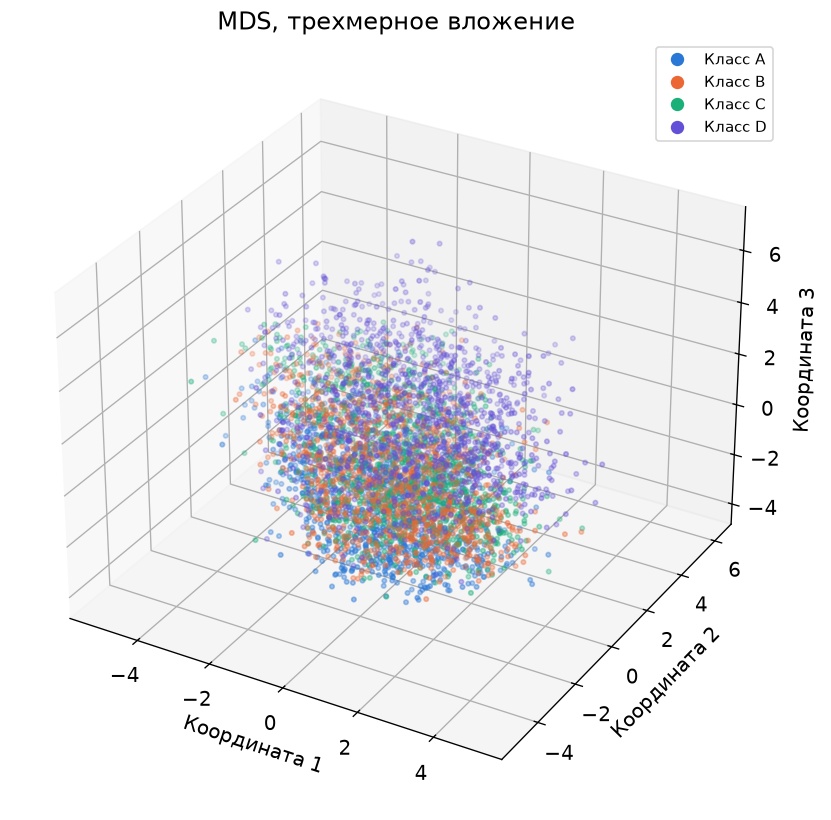

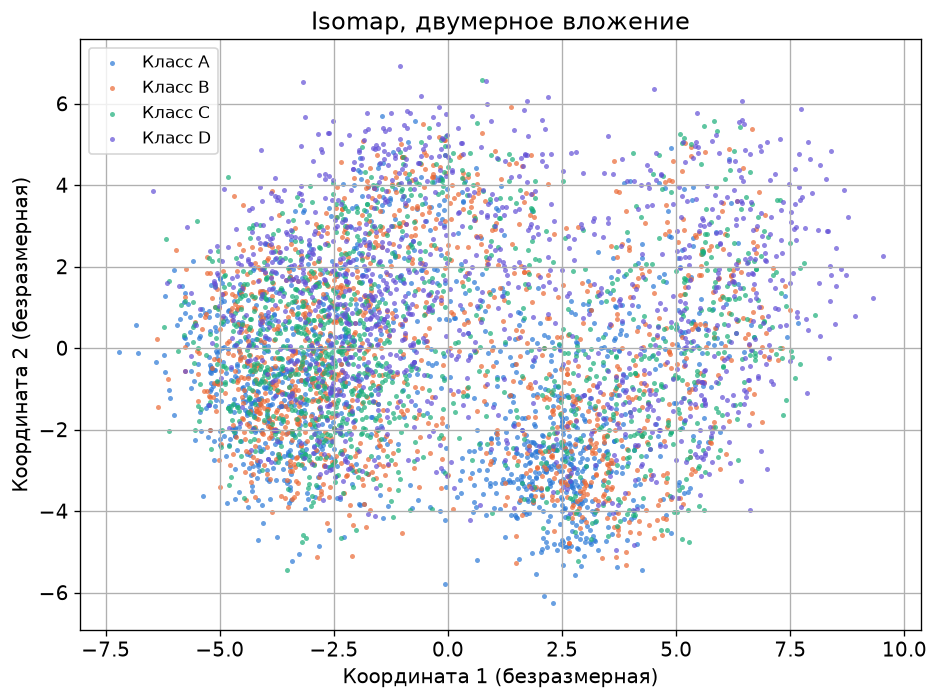

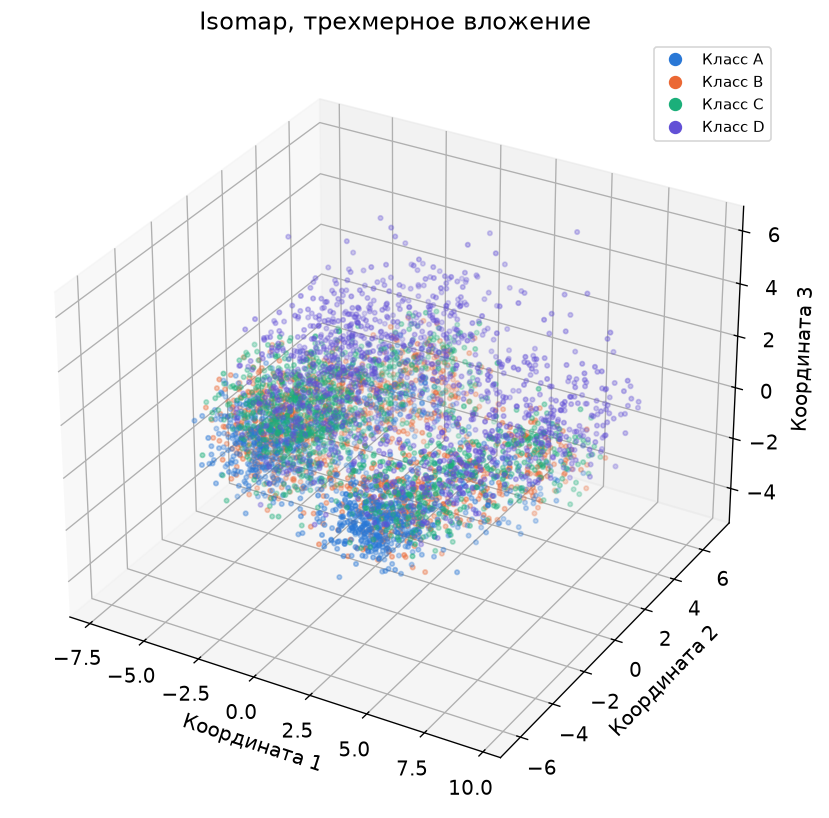

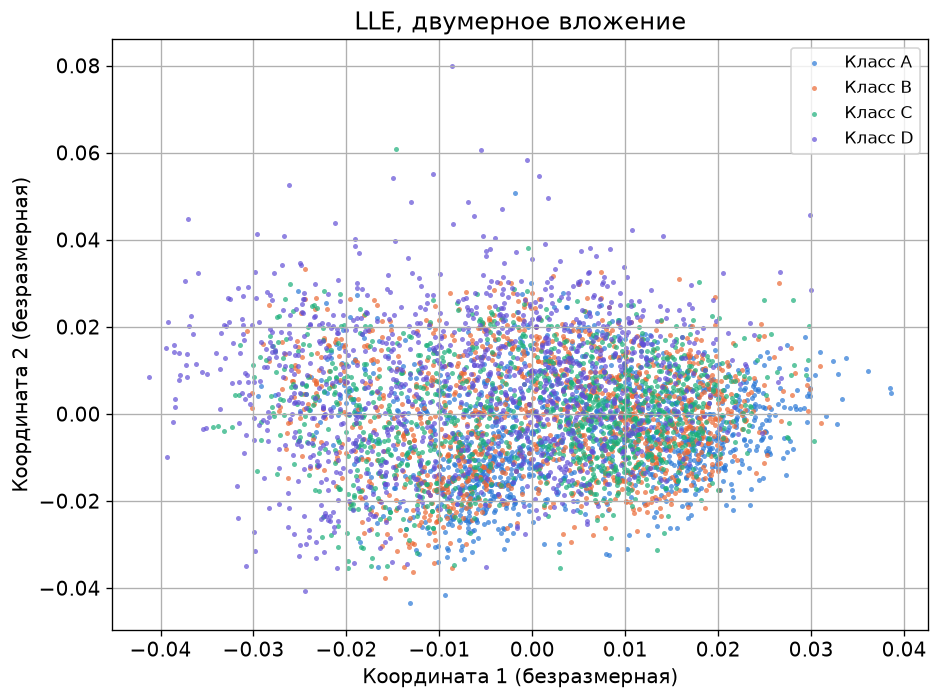

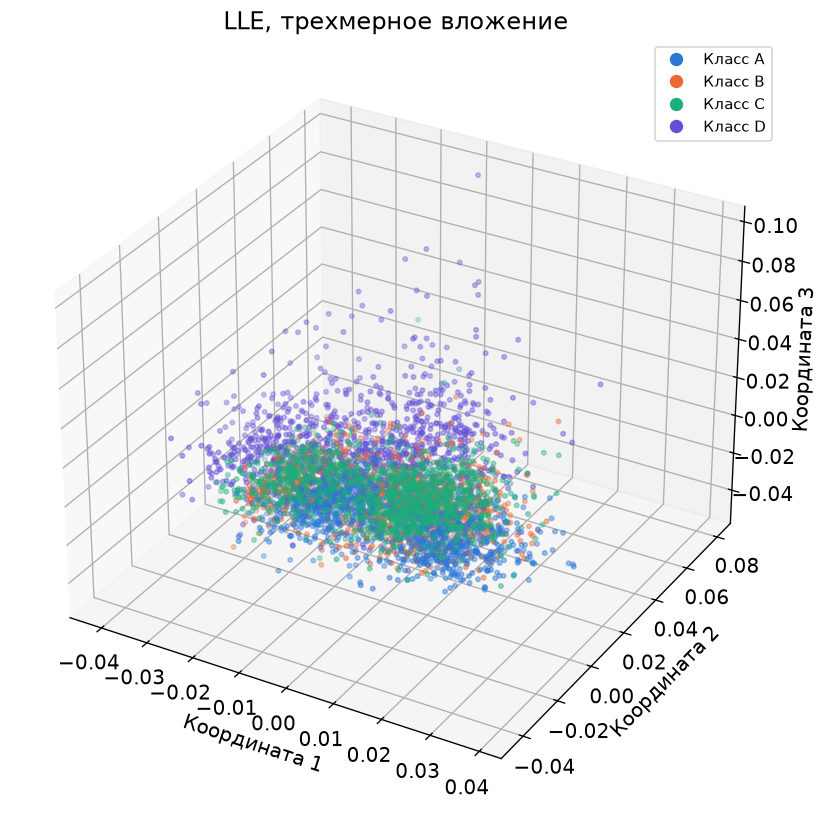

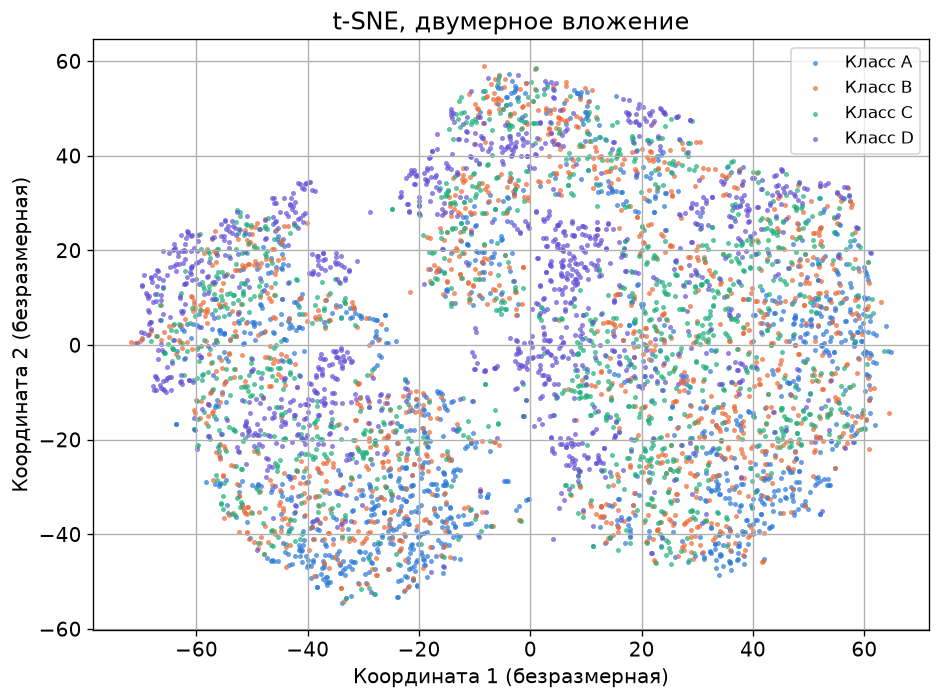

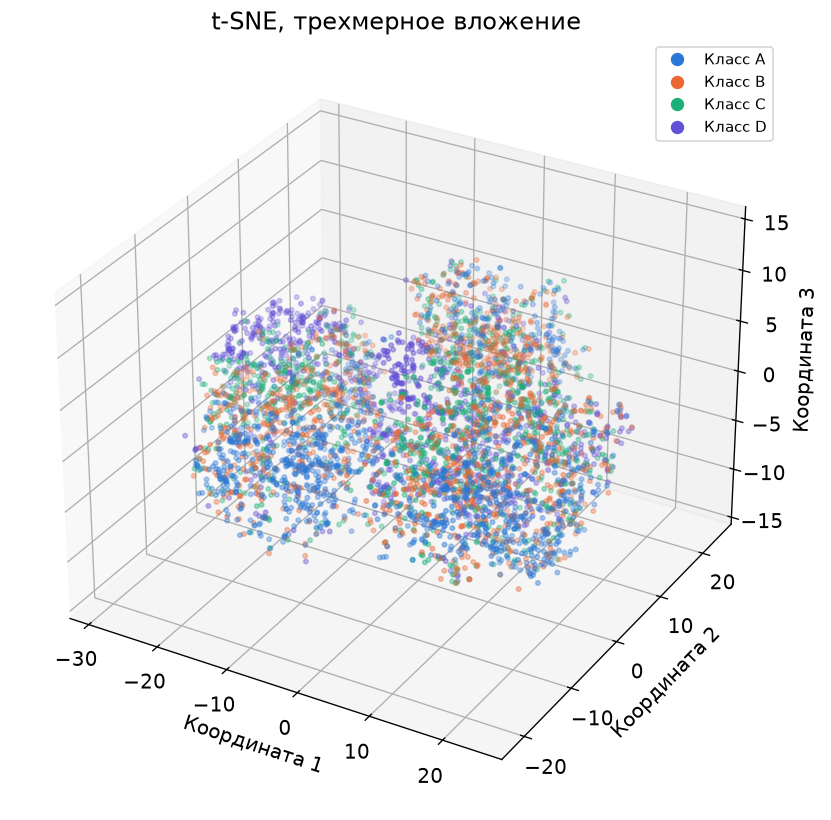

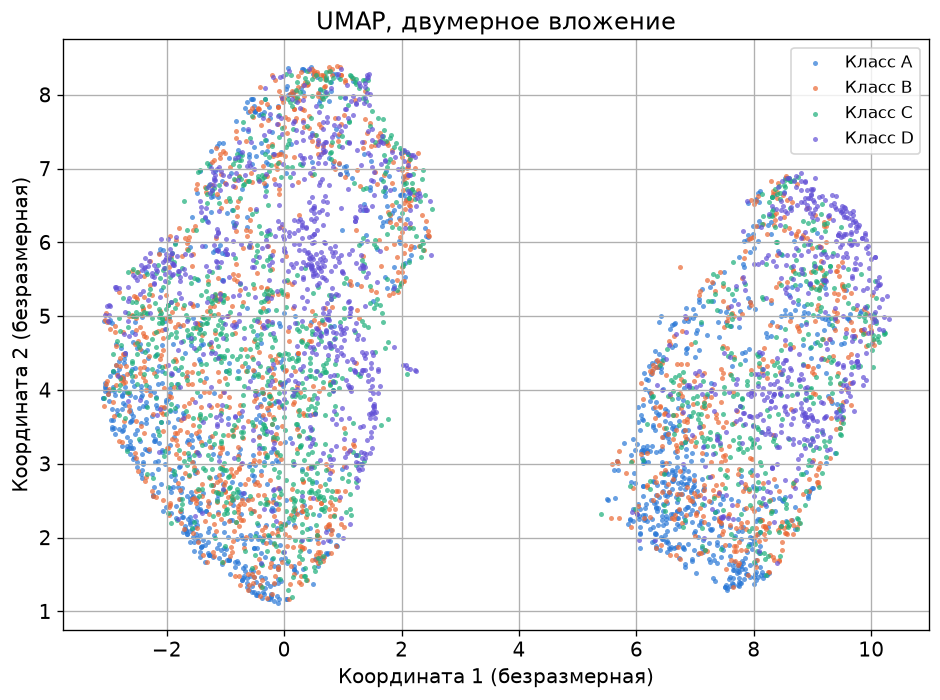

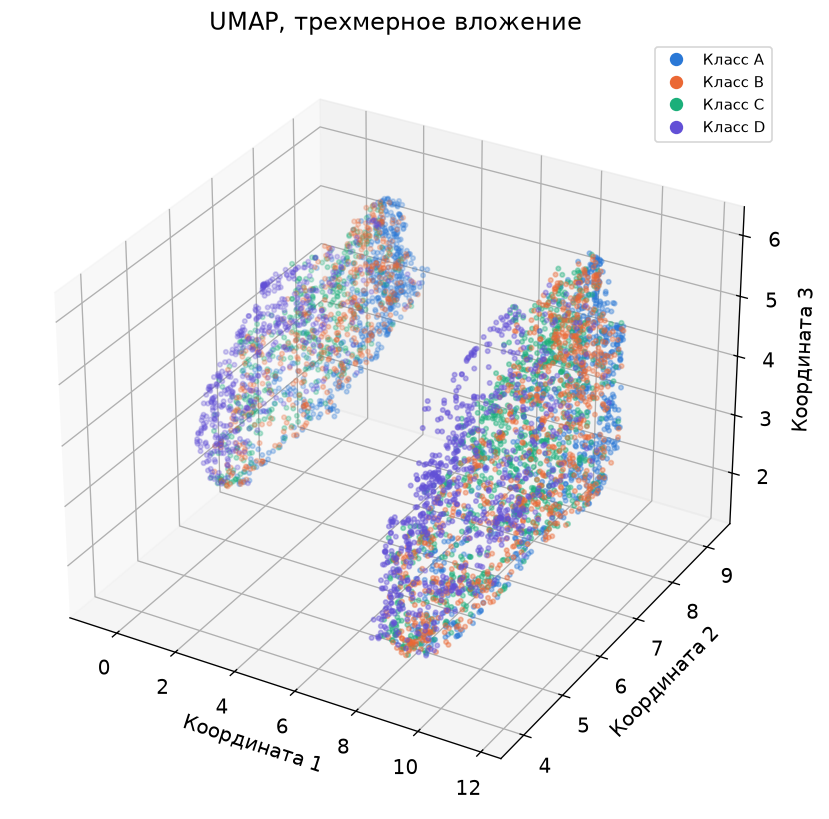

In [24]:
# Десять основных визуализаций: пять методов в 2D и 3D
for method in METHODS:
    slug = METHOD_SLUGS[method]

    figure, axis = plt.subplots(figsize=(8, 6))
    scatter_classes_2d(axis, embeddings_2d[method], y, f"{method}, двумерное вложение")
    axis.legend(loc="best", fontsize=10)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / f"lab4-2d-{slug}.png")
    plt.show()

    figure = plt.figure(figsize=(9, 7))
    axis = figure.add_subplot(111, projection="3d")
    for class_index, class_name in enumerate(CLASS_NAMES):
        mask = y == class_index
        axis.scatter(embeddings_3d[method][mask, 0], embeddings_3d[method][mask, 1],
                     embeddings_3d[method][mask, 2], s=7, alpha=0.7,
                     color=CLASS_COLORS[class_index], label=f"Класс {class_name}")
    axis.set_title(f"{method}, трехмерное вложение")
    axis.set_xlabel("Координата 1")
    axis.set_ylabel("Координата 2")
    axis.set_zlabel("Координата 3")
    axis.legend(handles=class_legend_handles(), loc="best", fontsize=9)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / f"lab4-3d-{slug}.png")
    plt.show()

**Результат:** на всех десяти картах (пять методов в 2D и 3D) классы не образуют отдельных областей.

- MDS: единое облако, класс A тяготеет к левому краю, D - к правому нижнему, но между ними плавный переход и широкая зона смешения.
- Isomap: картина близка к MDS, видны небольшие сгущения, геодезические расстояния не выделяют классы заметно лучше евклидовых.
- LLE: вытянутая горизонтальная полоса, вдоль которой классы меняются от A к D; четких границ нет, зато виден непрерывный градиент подготовленности.
- t-SNE: несколько плотных островов, но в каждом присутствуют все четыре класса; острова отражают не класс, а другие сочетания признаков.
- UMAP: два крупных плотных острова, внутри каждого цвета перемешаны; границы между островами резкие, но к классам они не привязаны.

Trustworthiness подтверждает визуальное впечатление: 0,9923 у t-SNE, 0,9419 у UMAP, 0,8843 у MDS, 0,8803 у Isomap и 0,8685 у LLE в 2D. Во всех случаях 3D-вложение сохраняет структуру лучше: от 0,9259 у LLE до 0,9960 у t-SNE. Высокий trustworthiness означает сохранение соседства, но не разделимость классов: у t-SNE соседство сохранено почти идеально, а цвета на карте все равно перемешаны.

### 7. Кластеризация K-means

Для каждого из десяти вложений выполняем K-means при K = 3, 4, 5, 6. Метки классов алгоритму не передаются, они используются только после кластеризации для анализа состава.

- Silhouette Score оценивает компактность и отделенность кластеров без истинных меток.
- ARI и NMI сравнивают кластеры с исходными классами.
- Для каждого кластера считаем количество и долю объектов каждого класса внутри кластера.

In [25]:
cluster_metrics = []
cluster_composition = []
cluster_assignments = {}

for method in METHODS:
    for dimensions, coordinates in [(2, embeddings_2d[method]), (3, embeddings_3d[method])]:
        for k in K_RANGE:
            model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
            cluster_labels = model.fit_predict(coordinates)
            cluster_assignments[(method, dimensions, k)] = cluster_labels

            cluster_metrics.append({
                "Метод": method,
                "Размерность": dimensions,
                "K": k,
                "Silhouette": round(float(silhouette_score(coordinates, cluster_labels)), 4),
                "ARI": round(float(adjusted_rand_score(y, cluster_labels)), 4),
                "NMI": round(float(normalized_mutual_info_score(y, cluster_labels)), 4),
            })

            # Состав кластеров: доли считаем внутри кластера
            for cluster in range(k):
                mask = cluster_labels == cluster
                cluster_size = int(mask.sum())
                for class_index, class_name in enumerate(CLASS_NAMES):
                    count = int((y[mask] == class_index).sum())
                    cluster_composition.append({
                        "Метод": method,
                        "Размерность": dimensions,
                        "K": k,
                        "Кластер": cluster,
                        "Класс": class_name,
                        "Объектов": count,
                        "Доля, %": round(100 * count / cluster_size, 2) if cluster_size else 0.0,
                    })

cluster_metrics = pd.DataFrame(cluster_metrics)
cluster_composition = pd.DataFrame(cluster_composition)
cluster_metrics.to_csv(RESULTS_DIR / "lab4-cluster-metrics.csv", index=False, encoding="utf-8")
cluster_composition.to_csv(RESULTS_DIR / "lab4-cluster-composition.csv", index=False, encoding="utf-8")

print("Всего запусков K-means:", len(cluster_metrics))
display(cluster_metrics.sort_values(["Метод", "Размерность", "K"]).reset_index(drop=True))

Всего запусков K-means: 40


,Метод,Размерность,K,Silhouette,ARI,NMI
0,Isomap,2,3,0.4216,0.0180,0.0217
1,Isomap,2,4,0.4370,0.0305,0.0367
2,Isomap,2,5,0.3938,0.0242,0.0297
3,Isomap,2,6,0.3620,0.0288,0.0399
4,Isomap,3,3,0.3504,0.0229,0.0275
5,Isomap,3,4,0.3537,0.0366,0.0436
6,Isomap,3,5,0.3210,0.0320,0.0386
7,Isomap,3,6,0.3251,0.0368,0.0497
8,LLE,2,3,0.3856,0.0266,0.0289
9,LLE,2,4,0.3716,0.0317,0.0372


In [26]:
# Подробный состав кластеров при K = 4 и лучший результат по ARI
example_tables = []
for method in METHODS:
    for dimensions in (2, 3):
        table = cluster_composition[
            (cluster_composition["Метод"] == method)
            & (cluster_composition["Размерность"] == dimensions)
            & (cluster_composition["K"] == CLUSTER_PLOT_K)
        ].copy()
        table["Случай"] = f"{method}, {dimensions}D, K={CLUSTER_PLOT_K}"
        example_tables.append(table)

example_composition = pd.concat(example_tables)
display(example_composition.pivot_table(
    index=["Случай", "Кластер"], columns="Класс", values="Доля, %", fill_value=0
).round(1))

best_ari_row = cluster_metrics.loc[cluster_metrics["ARI"].idxmax()]
print("Лучший ARI:", best_ari_row.to_dict())

Класс                       A     B     C     D
Случай          Кластер                        
Isomap, 2D, K=4 0        39.1  25.7  19.7  15.5
                1        27.6  26.7  29.8  15.9
                2        14.0  20.3  24.5  41.3
                3        14.1  24.6  22.9  38.5
Isomap, 3D, K=4 0        27.7  27.5  29.9  14.9
                1        40.2  25.7  19.7  14.4
                2        13.4  20.2  24.6  41.9
                3        13.3  23.4  22.6  40.7
LLE, 2D, K=4    0        15.8  24.4  23.1  36.7
                1        33.3  23.8  21.6  21.3
                2        13.1  20.7  23.9  42.3
                3        30.9  28.6  29.7  10.8
LLE, 3D, K=4    0        31.3  30.8  29.4   8.5
                1        29.3  22.0  22.3  26.4
                2         3.6   9.1  16.2  71.2
                3        22.4  28.2  26.1  23.3
MDS, 2D, K=4    0        14.1  24.3  25.0  36.6
                1        37.5  25.8  20.6  16.1
                2        14.5  20.1  24.4  41.1
                3        30.8  27.8  28.6  12.8
MDS, 3D, K=4    0        11.9  22.8  24.2  41.0
                1        40.8  27.2  20.1  11.9
                2        11.1  18.6  24.7  45.6
                3        30.7  28.3  29.2  11.8
UMAP, 2D, K=4   0        26.5  27.2  30.2  16.2
                1        42.6  26.1  18.3  13.0
                2        14.9  24.0  23.0  38.1
                3        15.4  20.3  24.4  39.9
UMAP, 3D, K=4   0        14.3  19.6  24.9  41.2
                1        27.9  28.0  30.0  14.2
                2        14.1  23.3  23.7  38.9
                3        43.9  26.7  17.9  11.6
t-SNE, 2D, K=4  0        40.8  25.1  18.6  15.5
                1        13.5  23.6  25.0  38.0
                2        16.7  20.6  24.6  38.0
                3        29.3  28.4  29.2  13.0
t-SNE, 3D, K=4  0        16.1  20.1  23.8  40.0
                1        28.2  27.9  29.8  14.2
                2        14.1  23.7  23.7  38.5
                3        42.4  26.1  19.2  12.3

Лучший ARI: {'Метод': 'MDS', 'Размерность': 3, 'K': 6, 'Silhouette': 0.2707, 'ARI': 0.0626, 'NMI': 0.084}


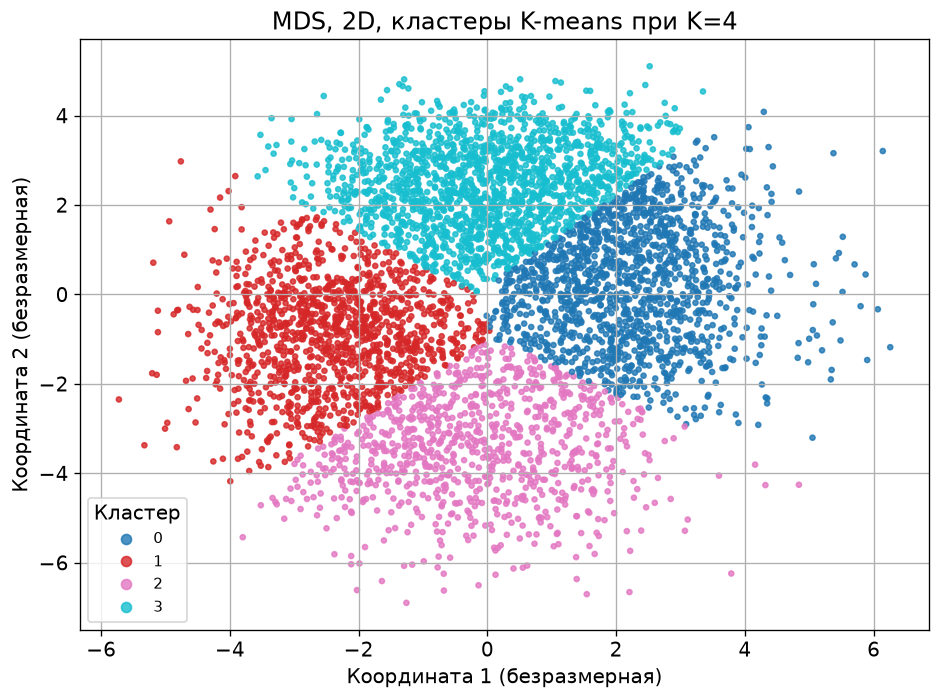

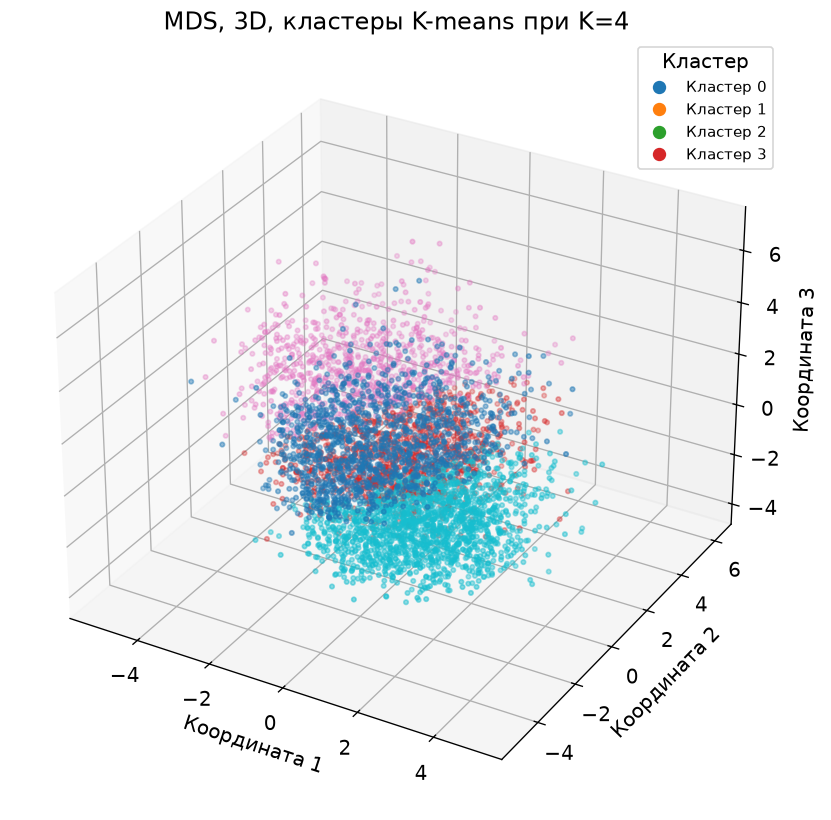

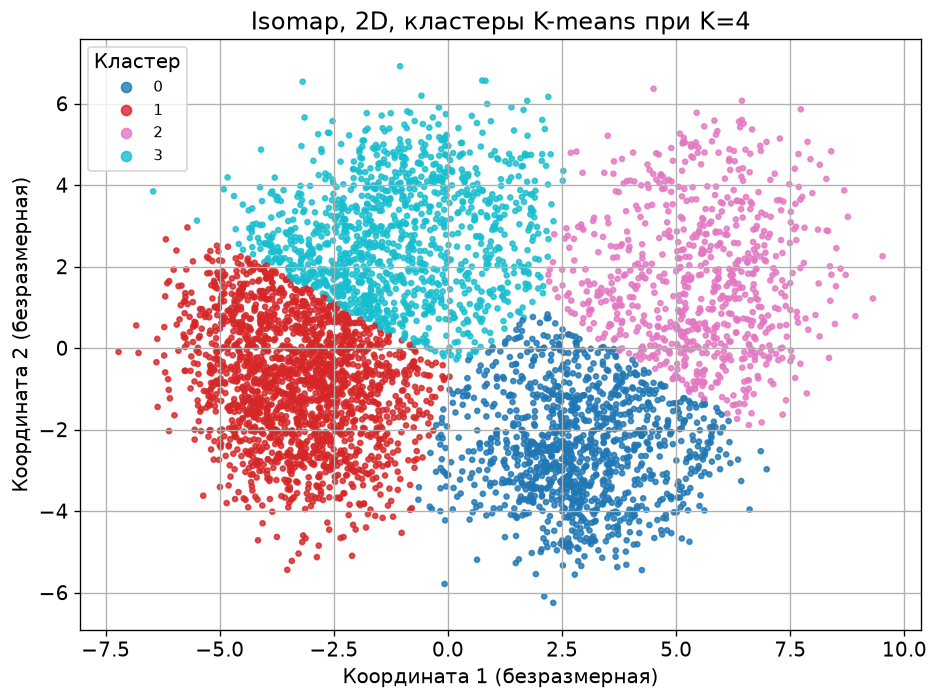

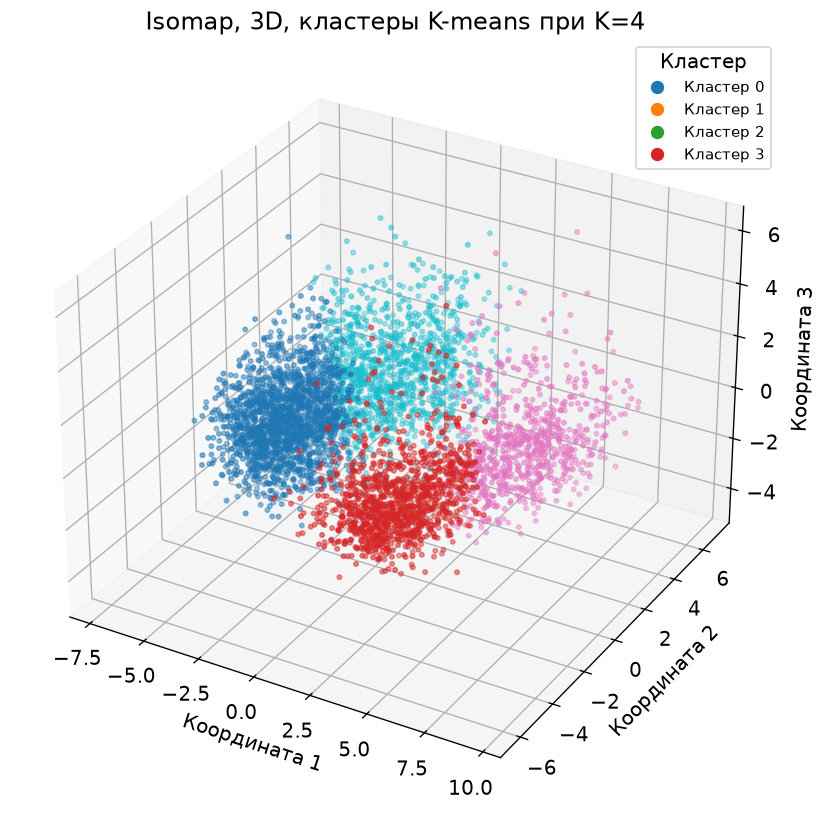

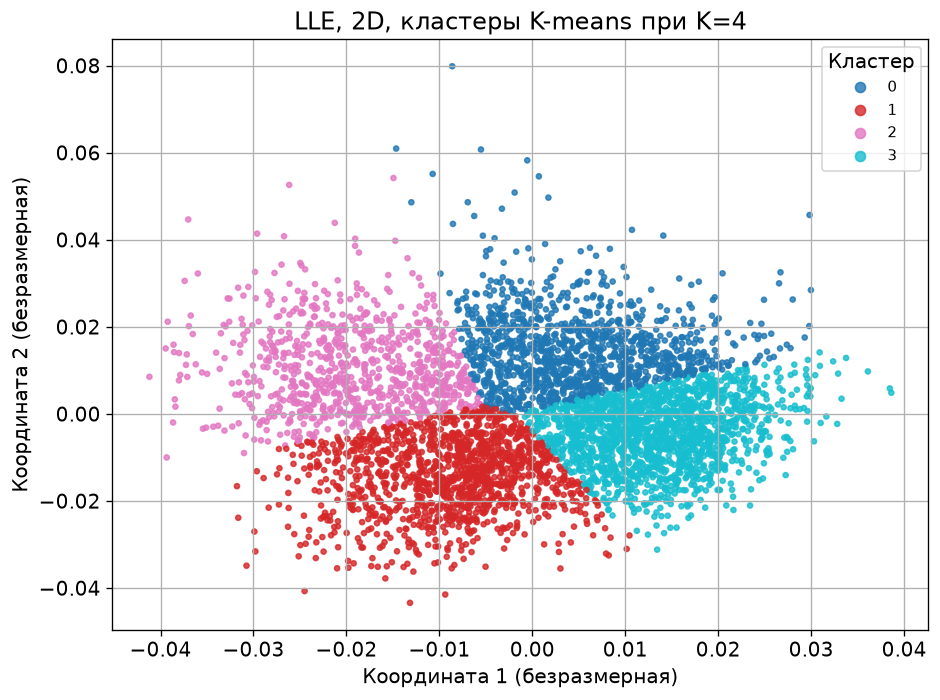

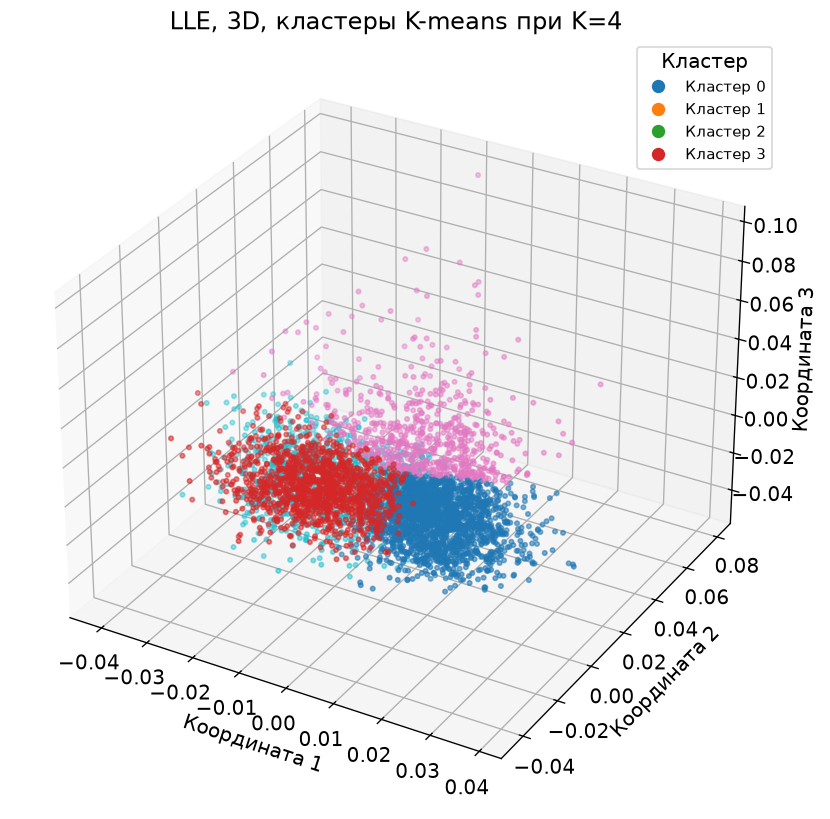

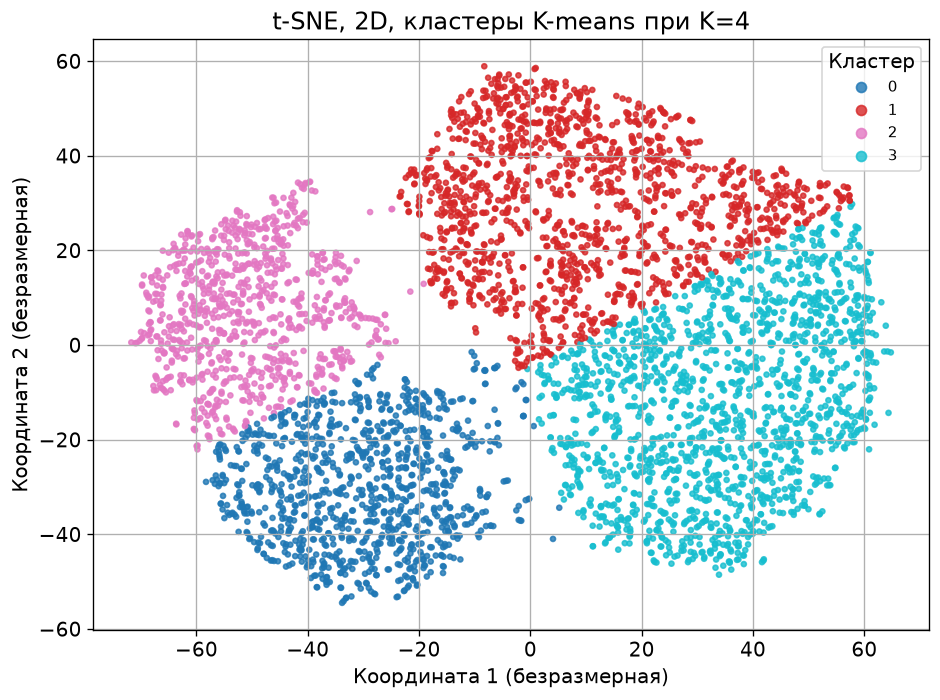

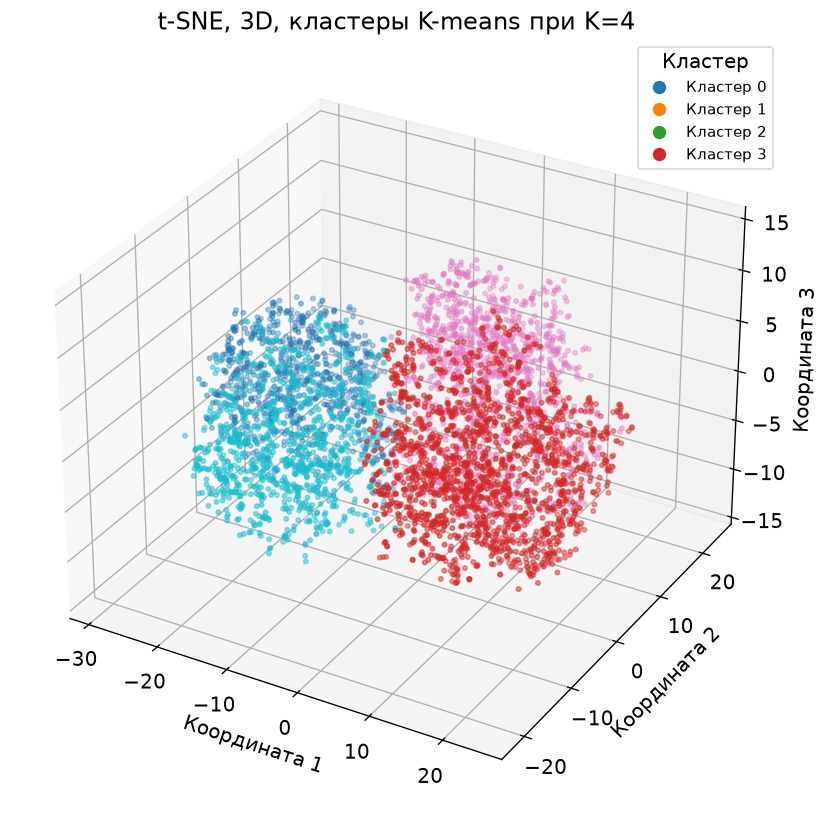

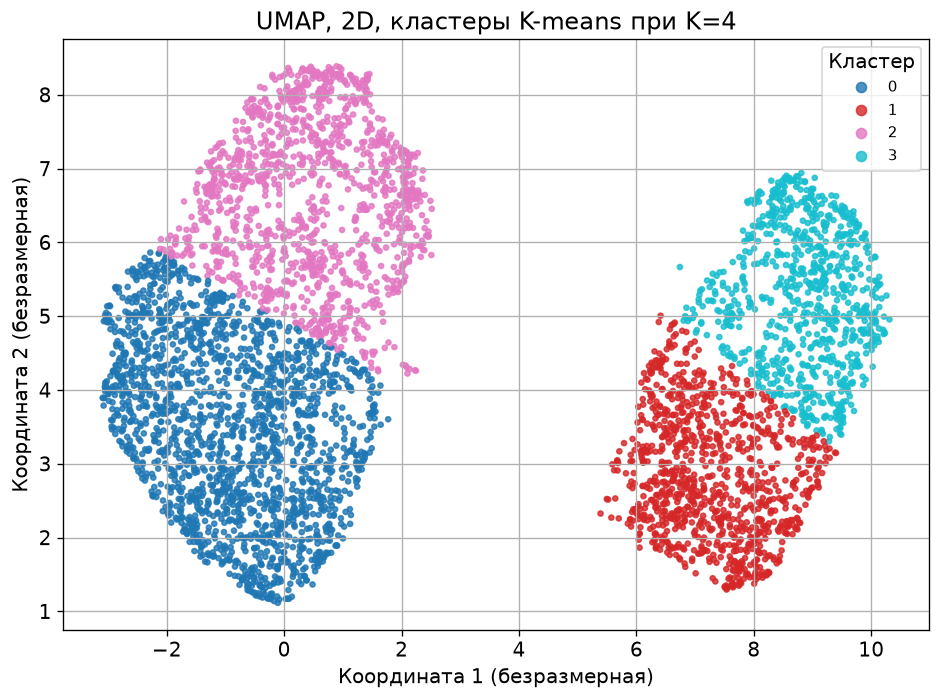

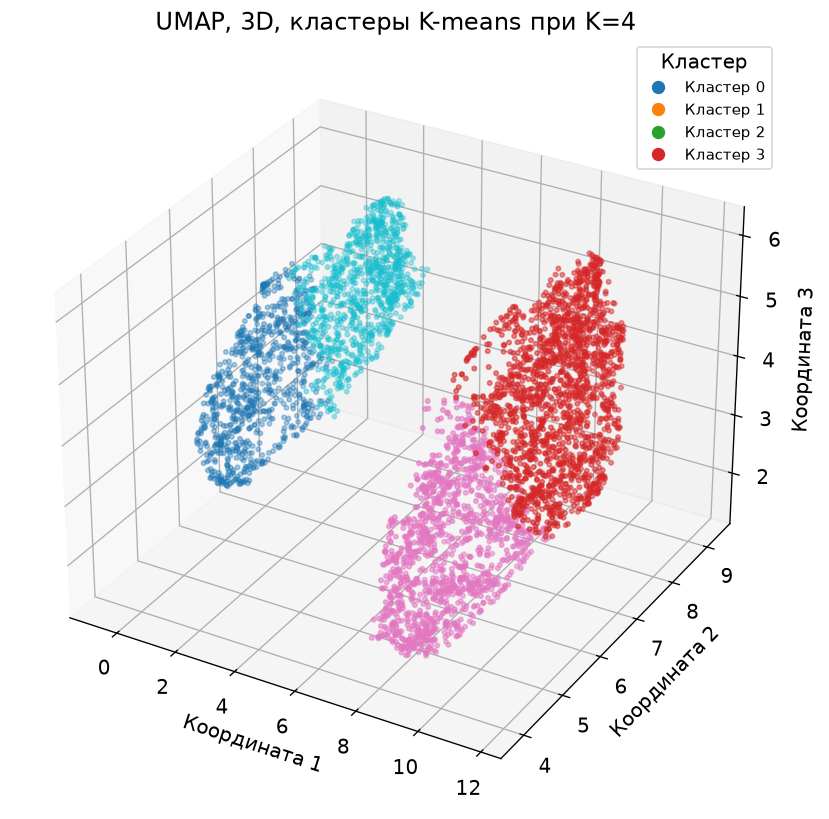

In [27]:
# Рисунки кластеров при K = 4: по одному на каждое вложение
for method in METHODS:
    slug = METHOD_SLUGS[method]
    for dimensions, coordinates in [(2, embeddings_2d[method]), (3, embeddings_3d[method])]:
        cluster_labels = cluster_assignments[(method, dimensions, CLUSTER_PLOT_K)]
        if dimensions == 2:
            figure, axis = plt.subplots(figsize=(8, 6))
            scatter = axis.scatter(coordinates[:, 0], coordinates[:, 1], c=cluster_labels,
                                   cmap="tab10", s=9, alpha=0.8)
            axis.set_title(f"{method}, 2D, кластеры K-means при K={CLUSTER_PLOT_K}")
            axis.set_xlabel("Координата 1 (безразмерная)")
            axis.set_ylabel("Координата 2 (безразмерная)")
            axis.legend(*scatter.legend_elements(), title="Кластер", loc="best", fontsize=9)
        else:
            figure = plt.figure(figsize=(9, 7))
            axis = figure.add_subplot(111, projection="3d")
            scatter = axis.scatter(coordinates[:, 0], coordinates[:, 1], coordinates[:, 2],
                                   c=cluster_labels, cmap="tab10", s=7, alpha=0.8)
            axis.set_title(f"{method}, 3D, кластеры K-means при K={CLUSTER_PLOT_K}")
            axis.set_xlabel("Координата 1")
            axis.set_ylabel("Координата 2")
            axis.set_zlabel("Координата 3")
            cluster_handles = [
                Line2D([0], [0], marker="o", linestyle="", color=plt.cm.tab10(index / 10),
                       label=f"Кластер {index}", markersize=7)
                for index in range(CLUSTER_PLOT_K)
            ]
            axis.legend(handles=cluster_handles, title="Кластер", loc="best", fontsize=9)
        figure.tight_layout()
        figure.savefig(FIGURES_DIR / f"lab4-clusters-{dimensions}d-{slug}.png")
        plt.show()

**Результат:** выполнено 40 запусков K-means: пять методов, две размерности, K от 3 до 6. Кластеры геометрически компактны: лучший Silhouette 0,5474 у UMAP 2D при K=3, затем 0,4449 у t-SNE 2D и 0,4370 у Isomap 2D. С ростом K компактность обычно падает, потому что области дробятся.

Совпадение с классами очень слабое. Максимальный ARI 0,0626 достигается у MDS 3D при K=6 (NMI 0,0840), затем идут LLE 3D K=4 (0,0532), UMAP 3D K=6 (0,0408), Isomap 3D K=6 и t-SNE 3D K=4 (по 0,0368). Значения близки к нулю: кластеры почти не соответствуют классам подготовленности.

Состав кластеров это подтверждает. В MDS 2D при K=4 кластеры 0 и 2 на 36,6 % и 41,1 % состоят из класса D, кластеры 1 и 3 на 37,5 % и 30,8 % - из класса A. Но ни один кластер не состоит из одного класса, а доля главного класса при K=4 не превышает 43 % на двумерных картах. K-means делит карту по геометрической близости, а класс подготовленности - это внешняя метка, которая с геометрией напрямую не совпадает.

### 8. Классификация на двумерных вложениях

Для каждого из пяти двумерных вложений обучаем Decision Tree и Random Forest. Вход - две координаты вложения, целевая переменная - исходный класс. Разбиение 70 / 30 со стратификацией, гиперпараметры подбираются кросс-валидацией на обучающей части, тест используется один раз.

Вложения построены по всем 5 000 объектам, включая тестовые. Поэтому эти оценки сравнивают представления между собой, но не являются независимой проверкой обобщения на новых людей. Для Isomap и UMAP ниже будет отдельная строгая проверка.

In [28]:
DT_PARAMETERS = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
}
RF_PARAMETERS = {
    "max_depth": [5, 10, None],
    "max_features": ["sqrt", 1.0],
}


def fit_and_evaluate_models(evaluation, method, X_learn, y_learn, X_check, y_check):
    """Подбирает DT и RF по кросс-валидации и оценивает их на отложенной части."""
    rows = []
    per_class_rows = []
    fitted = {}

    # Базовая модель: самый частый класс
    dummy_model = DummyClassifier(strategy="most_frequent").fit(X_learn, y_learn)
    dummy_predictions = dummy_model.predict(X_check)
    rows.append(classification_metrics(evaluation, method, "Dummy", y_check, dummy_predictions))
    per_class_rows.extend(per_class_metrics(evaluation, method, "Dummy", y_check, dummy_predictions))
    fitted["Dummy"] = dummy_model

    tree_search = GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        DT_PARAMETERS,
        cv=CV,
        scoring="f1_macro",
        n_jobs=1,
    )
    tree_search.fit(X_learn, y_learn)
    tree_predictions = tree_search.best_estimator_.predict(X_check)
    rows.append(classification_metrics(
        evaluation, method, "Decision Tree", y_check, tree_predictions, str(tree_search.best_params_)
    ))
    per_class_rows.extend(per_class_metrics(evaluation, method, "Decision Tree", y_check, tree_predictions))
    fitted["Decision Tree"] = tree_search.best_estimator_

    forest_search = GridSearchCV(
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        RF_PARAMETERS,
        cv=CV,
        scoring="f1_macro",
        n_jobs=1,
    )
    forest_search.fit(X_learn, y_learn)
    forest_predictions = forest_search.best_estimator_.predict(X_check)
    rows.append(classification_metrics(
        evaluation, method, "Random Forest", y_check, forest_predictions, str(forest_search.best_params_)
    ))
    per_class_rows.extend(per_class_metrics(evaluation, method, "Random Forest", y_check, forest_predictions))
    fitted["Random Forest"] = forest_search.best_estimator_

    return rows, per_class_rows, fitted


classification_rows = []
classification_per_class = []
fitted_models = {}
classification_predictions = {}

for method in METHODS:
    coordinates = embeddings_2d[method]
    rows, per_class_rows, fitted = fit_and_evaluate_models(
        "transductive", method, coordinates[train_idx], y[train_idx], coordinates[test_idx], y[test_idx]
    )
    classification_rows.extend(rows)
    classification_per_class.extend(per_class_rows)
    for model_name, model in fitted.items():
        fitted_models[(method, model_name)] = model
        classification_predictions[(method, model_name)] = model.predict(coordinates[test_idx])

classification_metrics_table = pd.DataFrame(classification_rows)
classification_per_class_table = pd.DataFrame(classification_per_class)
classification_metrics_table.to_csv(RESULTS_DIR / "lab4-classification-metrics.csv", index=False, encoding="utf-8")
classification_per_class_table.to_csv(RESULTS_DIR / "lab4-classification-per-class.csv", index=False, encoding="utf-8")

display(classification_metrics_table[classification_metrics_table["Модель"] != "Dummy"])

,Оценка,Метод,Модель,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,Параметры
1,transductive,MDS,Decision Tree,0.3907,0.3881,0.3907,0.3864,0.3881,0.3907,0.3864,"{'max_depth': 7, 'min_samples_leaf': 20}"
2,transductive,MDS,Random Forest,0.4080,0.3983,0.4080,0.3944,0.3983,0.4080,0.3944,"{'max_depth': 5, 'max_features': 1.0}"
4,transductive,Isomap,Decision Tree,0.3653,0.3656,0.3653,0.3649,0.3656,0.3653,0.3649,"{'max_depth': 7, 'min_samples_leaf': 10}"
5,transductive,Isomap,Random Forest,0.3820,0.3685,0.3820,0.3506,0.3685,0.3820,0.3506,"{'max_depth': 5, 'max_features': 'sqrt'}"
7,transductive,LLE,Decision Tree,0.3787,0.3761,0.3787,0.3709,0.3761,0.3787,0.3709,"{'max_depth': 5, 'min_samples_leaf': 20}"
8,transductive,LLE,Random Forest,0.3987,0.3958,0.3987,0.3937,0.3958,0.3987,0.3937,"{'max_depth': 10, 'max_features': 'sqrt'}"
10,transductive,t-SNE,Decision Tree,0.5080,0.5052,0.5080,0.5065,0.5052,0.5080,0.5065,"{'max_depth': None, 'min_samples_leaf': 10}"
11,transductive,t-SNE,Random Forest,0.5247,0.5190,0.5247,0.5211,0.5190,0.5247,0.5211,"{'max_depth': None, 'max_features': 'sqrt'}"
13,transductive,UMAP,Decision Tree,0.4540,0.4447,0.4540,0.4469,0.4447,0.4540,0.4469,"{'max_depth': 7, 'min_samples_leaf': 5}"
14,transductive,UMAP,Random Forest,0.4713,0.4594,0.4713,0.4625,0.4594,0.4713,0.4625,"{'max_depth': 10, 'max_features': 'sqrt'}"


**Результат:** все десять моделей (пять методов, DT и RF) заметно выше случайного уровня 0,2500, но ни одна не приближается к ориентиру 0,80.

| Метод | DT Accuracy | RF Accuracy | DT F1 macro | RF F1 macro |
|---|---|---|---|---|
| MDS | 0,3907 | 0,4080 | 0,3864 | 0,3944 |
| Isomap | 0,3653 | 0,3820 | 0,3649 | 0,3506 |
| LLE | 0,3787 | 0,3987 | 0,3709 | 0,3937 |
| t-SNE | 0,5080 | 0,5247 | 0,5065 | 0,5211 |
| UMAP | 0,4540 | 0,4713 | 0,4469 | 0,4625 |

Random Forest выигрывает у Decision Tree по Accuracy во всех пяти случаях: ансамбль устойчивее к шуму координат. Лучший результат - t-SNE с Random Forest (Accuracy 0,5247, F1 macro 0,5211), затем UMAP с Random Forest (0,4713). Хуже всех Isomap (0,3653 у DT и 0,3820 у RF).

Порядок методов по классификации почти совпадает с порядком по trustworthiness: t-SNE > UMAP > MDS > LLE > Isomap, переставлены только LLE и Isomap. Значит, качество двумерного представления действительно определяет, сколько информации о классе остается доступным классификатору.

Подобранные гиперпараметры: для t-SNE деревья не ограничены по глубине (DT: max_depth=None, min_samples_leaf=10; RF: max_depth=None, max_features="sqrt"), для MDS - мелкие (DT: 7/20; RF: 5/1.0). Плотные острова t-SNE требуют более сложных границ, плавное облако MDS - наоборот.

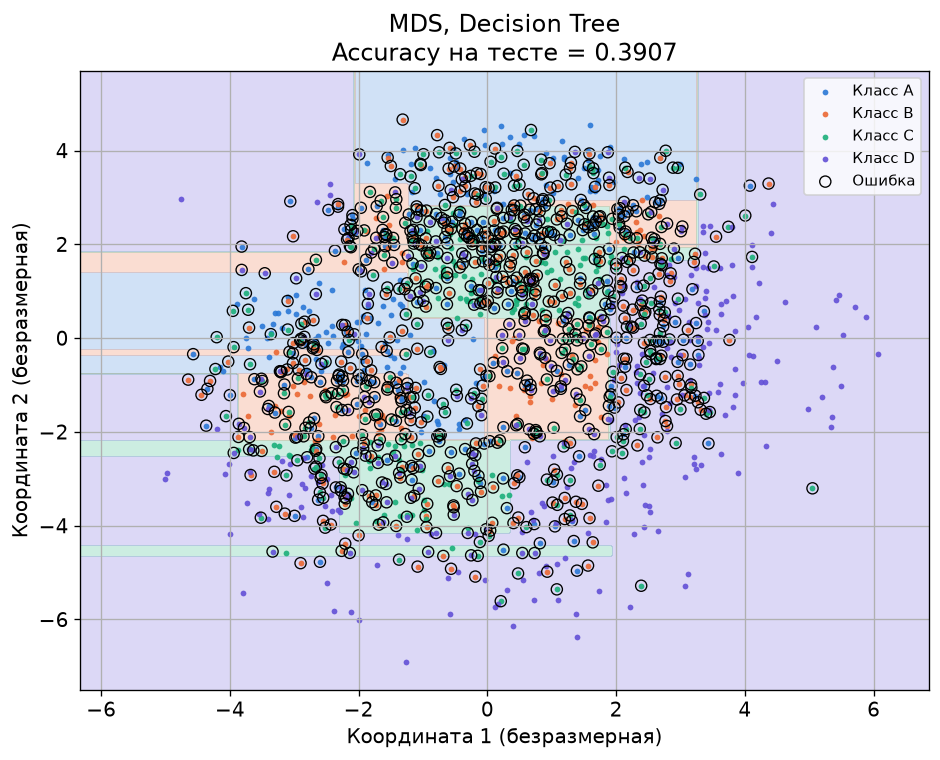

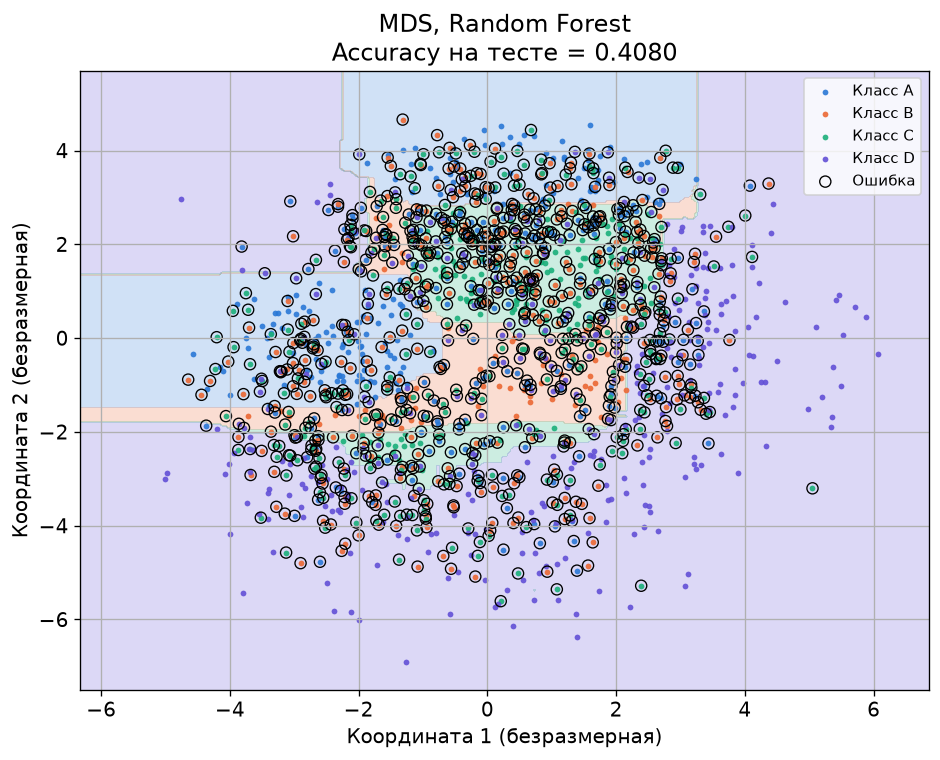

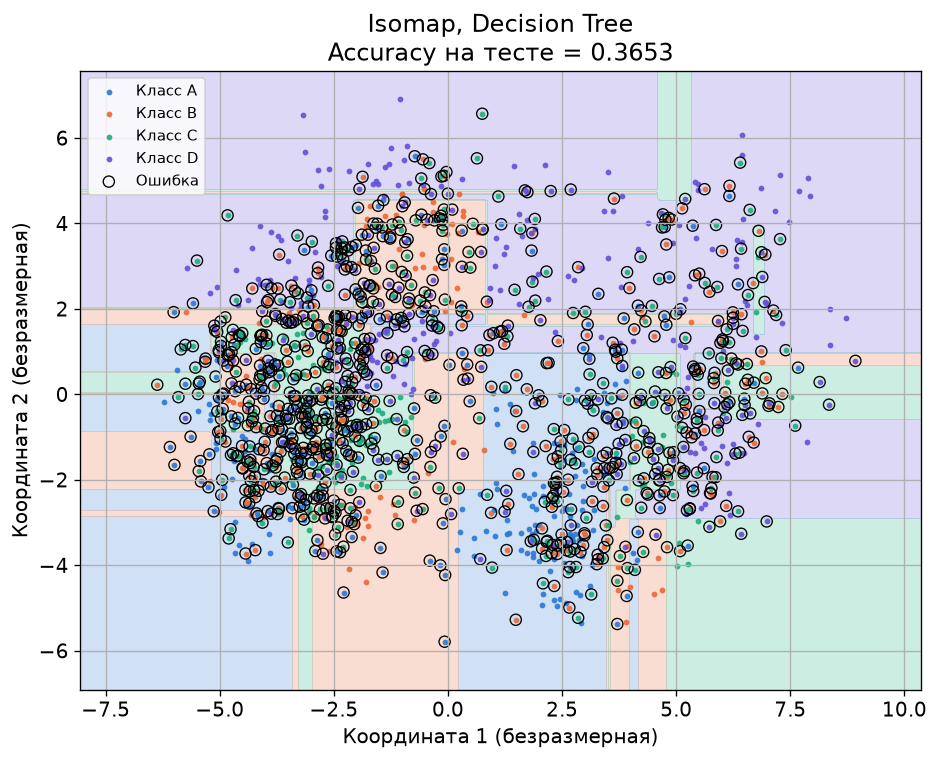

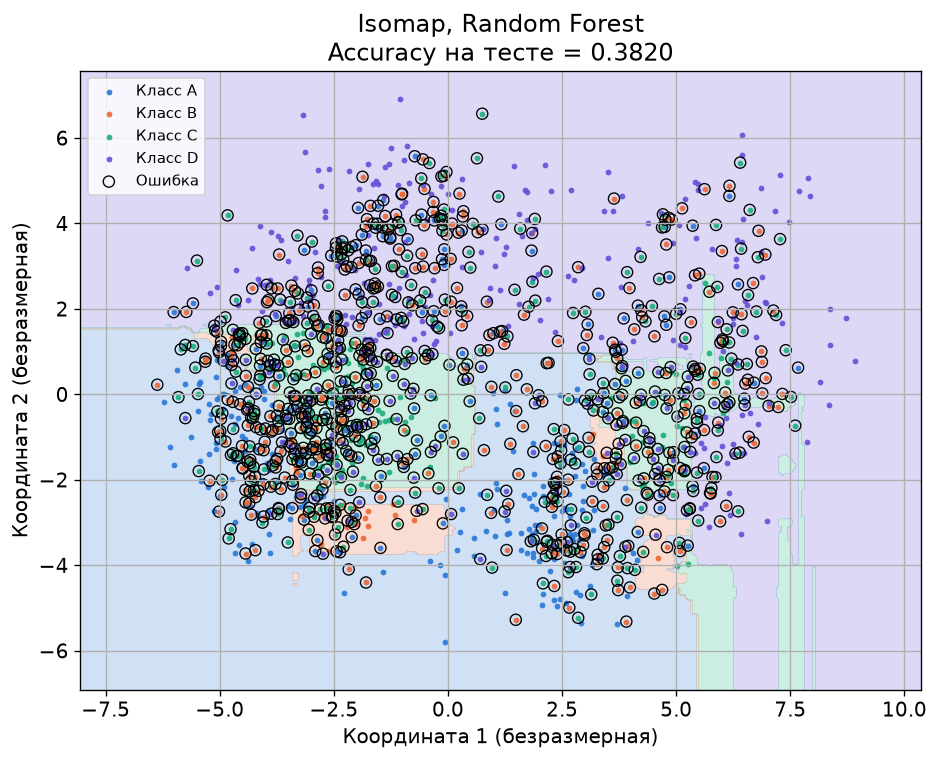

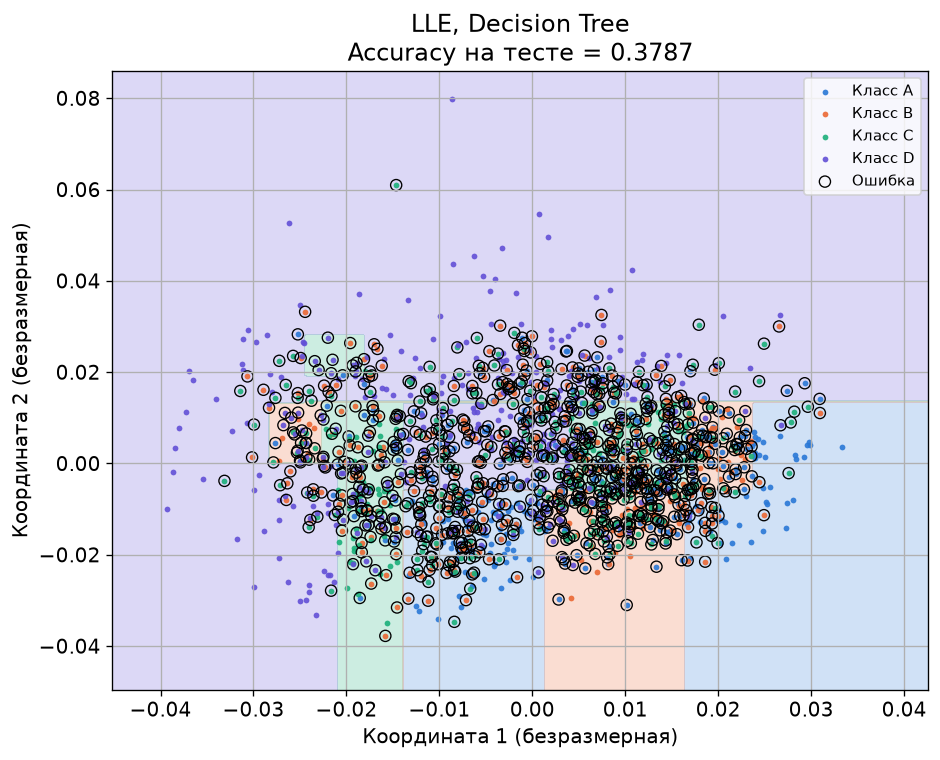

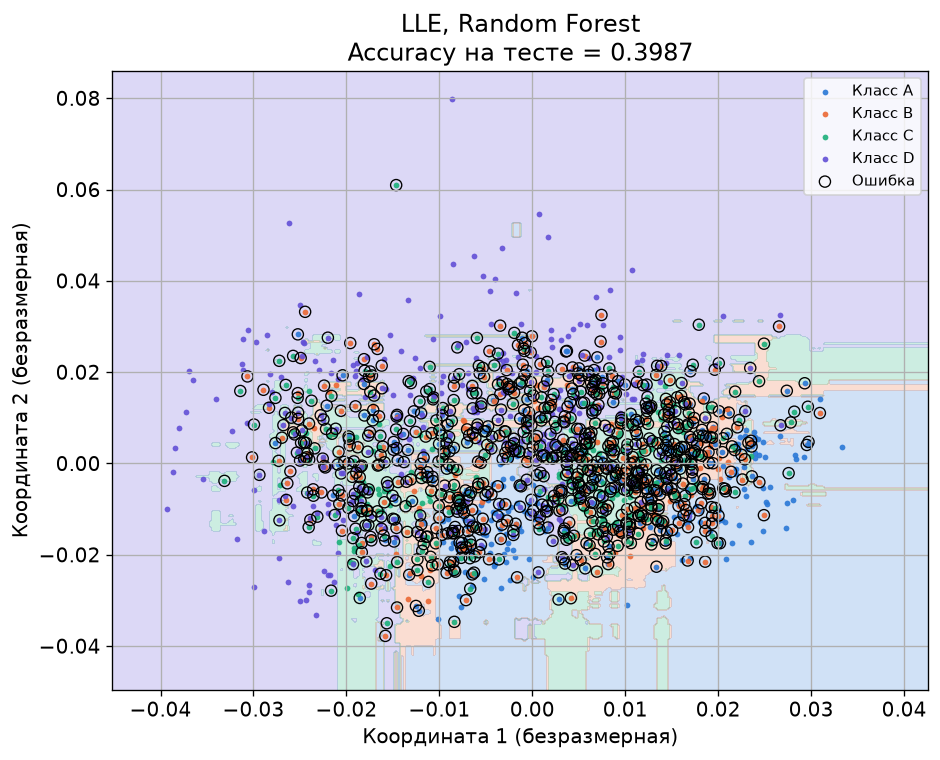

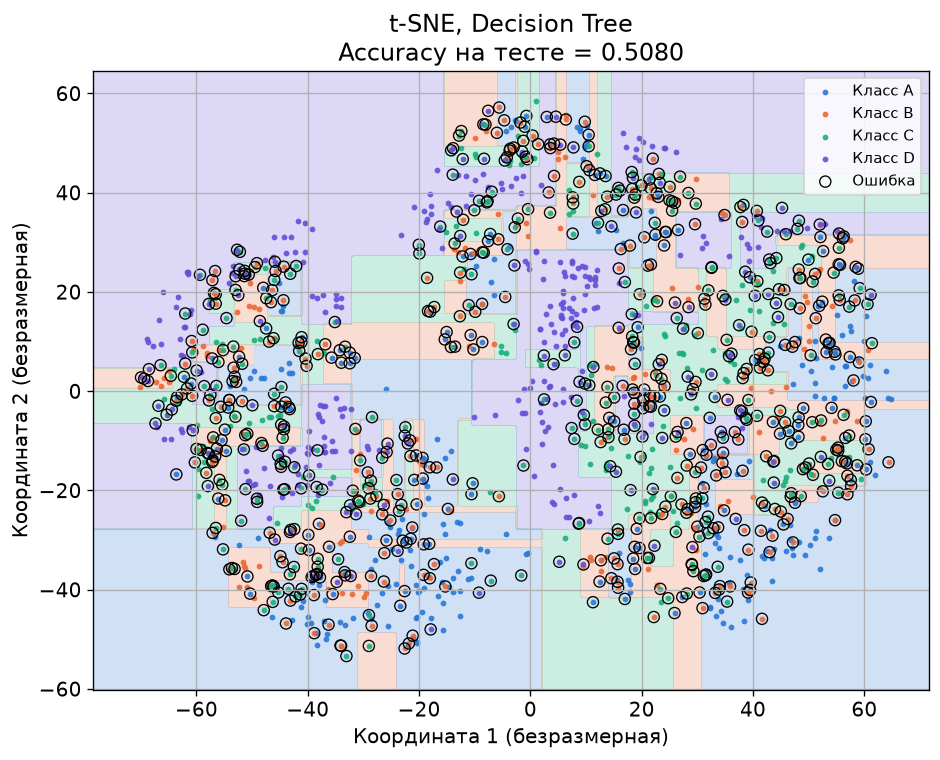

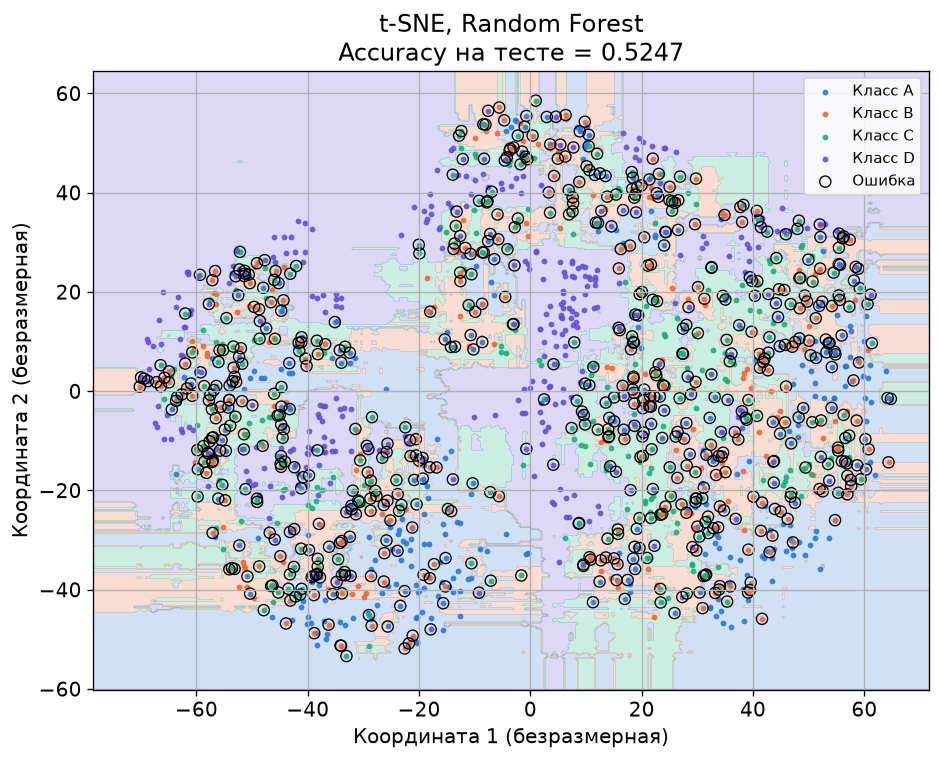

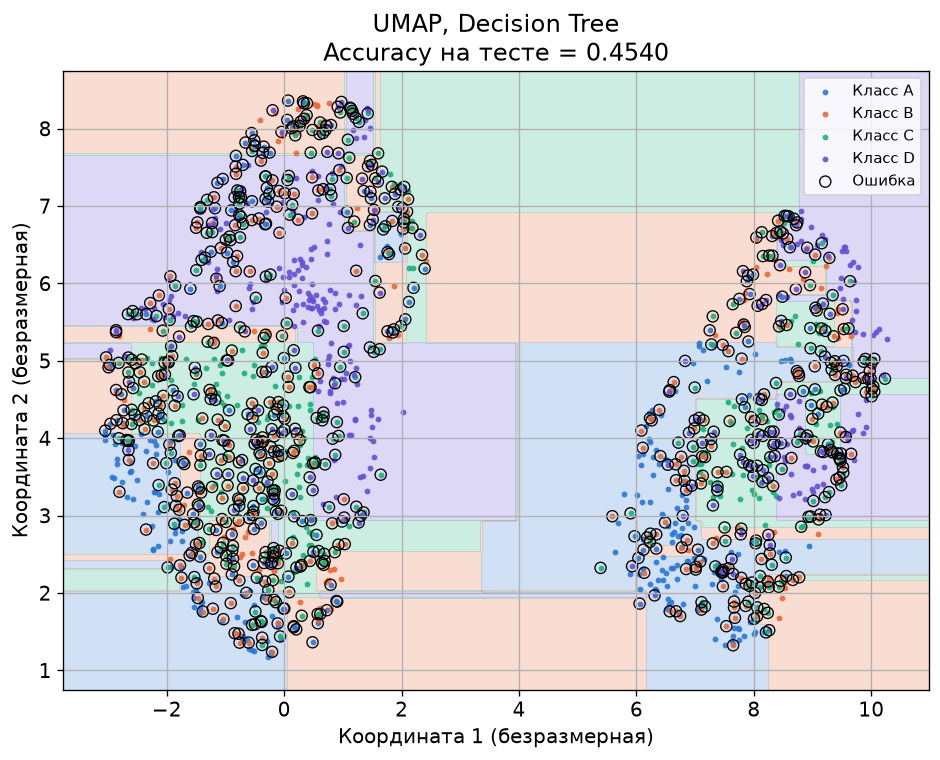

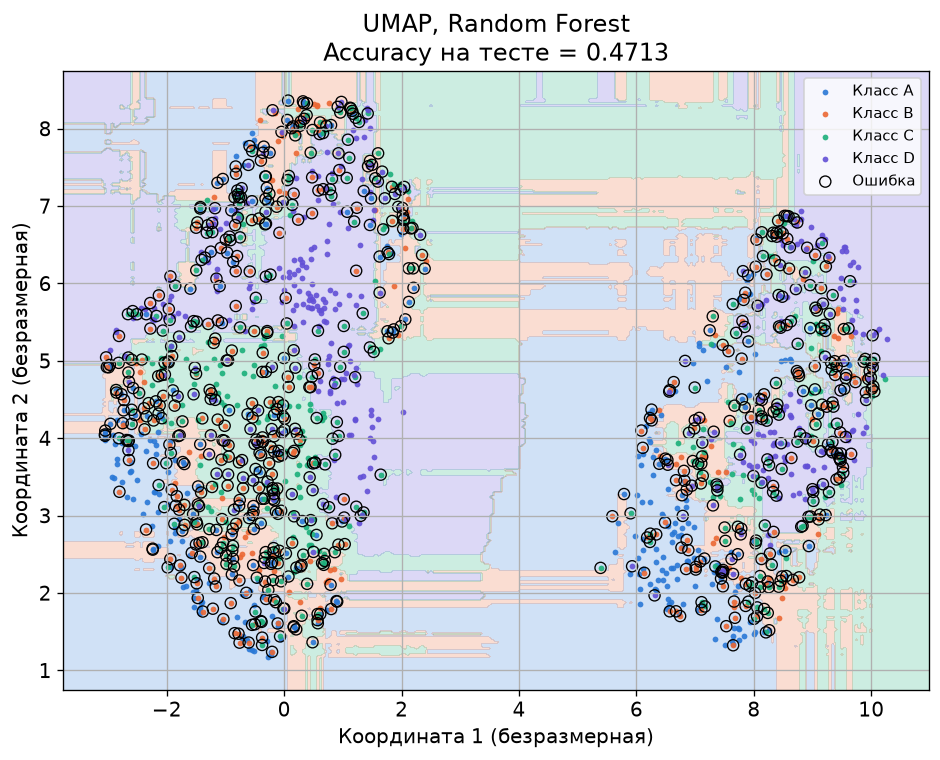

In [29]:
# Границы решений: фон - предсказанные области, точки - тестовая выборка
for method in METHODS:
    slug = METHOD_SLUGS[method]
    coordinates = embeddings_2d[method]
    test_coordinates = coordinates[test_idx]

    x_min, x_max = coordinates[:, 0].min(), coordinates[:, 0].max()
    y_min, y_max = coordinates[:, 1].min(), coordinates[:, 1].max()
    x_margin = 0.05 * (x_max - x_min)
    y_margin = 0.05 * (y_max - y_min)

    grid_x, grid_y = np.meshgrid(
        np.linspace(x_min - x_margin, x_max + x_margin, 300),
        np.linspace(y_min - y_margin, y_max + y_margin, 300),
    )
    grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

    for model_name in ["Decision Tree", "Random Forest"]:
        model = fitted_models[(method, model_name)]
        predicted_regions = model.predict(grid_points).reshape(grid_x.shape)
        predictions = classification_predictions[(method, model_name)]
        accuracy = accuracy_score(y[test_idx], predictions)

        figure, axis = plt.subplots(figsize=(8, 6.5))
        axis.contourf(grid_x, grid_y, predicted_regions, alpha=0.22,
                      levels=np.arange(-0.5, NUMBER_OF_CLASSES + 0.5, 1), colors=CLASS_COLORS)
        for class_index, class_name in enumerate(CLASS_NAMES):
            mask = y[test_idx] == class_index
            axis.scatter(test_coordinates[mask, 0], test_coordinates[mask, 1], s=12, alpha=0.9,
                         color=CLASS_COLORS[class_index], label=f"Класс {class_name}", linewidths=0)
        # Ошибочные объекты обводим черным кружком
        errors = predictions != y[test_idx]
        axis.scatter(test_coordinates[errors, 0], test_coordinates[errors, 1], s=45,
                     facecolors="none", edgecolors="black", linewidths=0.8, label="Ошибка")
        axis.set_title(f"{method}, {model_name}\nAccuracy на тесте = {accuracy:.4f}")
        axis.set_xlabel("Координата 1 (безразмерная)")
        axis.set_ylabel("Координата 2 (безразмерная)")
        axis.legend(loc="best", fontsize=9)
        figure.tight_layout()
        file_name = f"lab4-boundary-{slug}-{'dt' if model_name == 'Decision Tree' else 'rf'}.png"
        figure.savefig(FIGURES_DIR / file_name)
        plt.show()

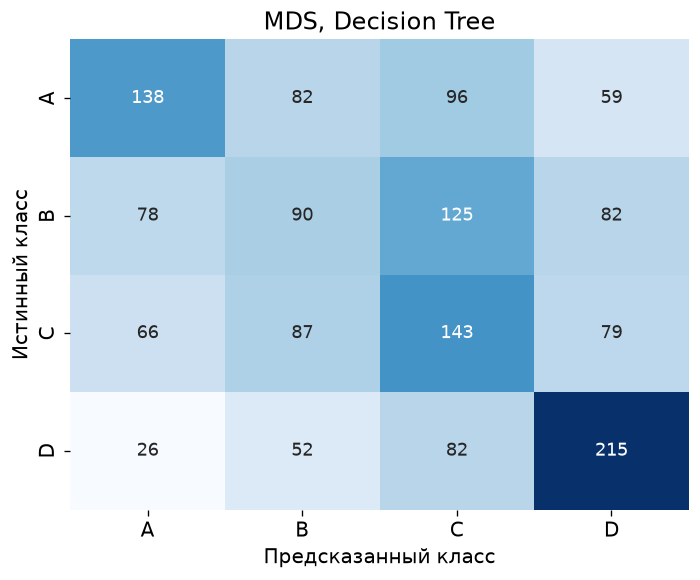

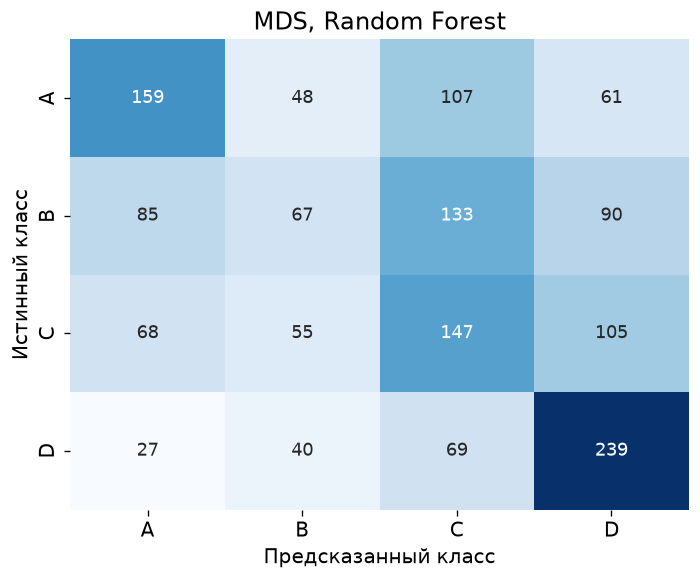

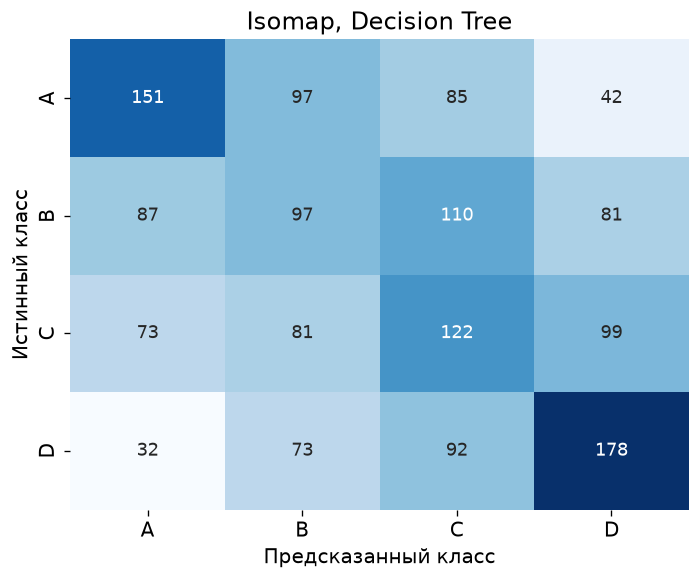

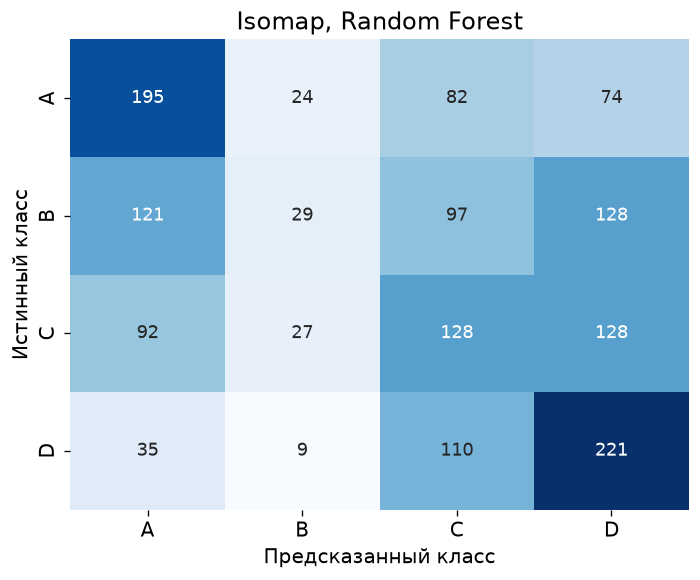

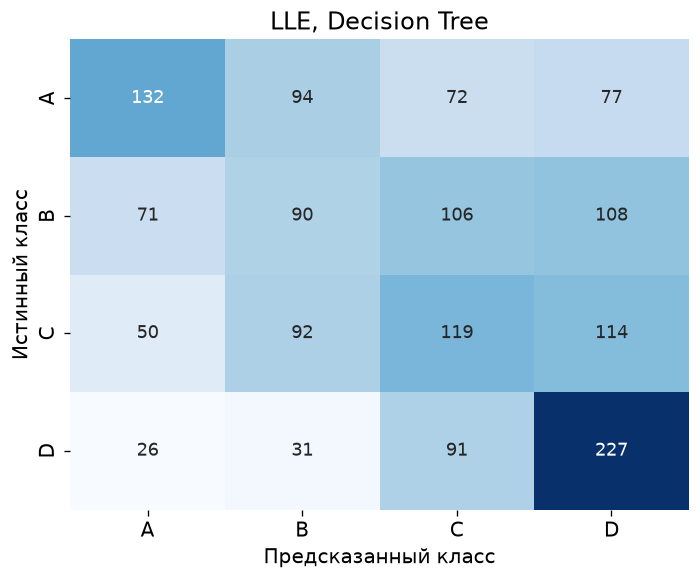

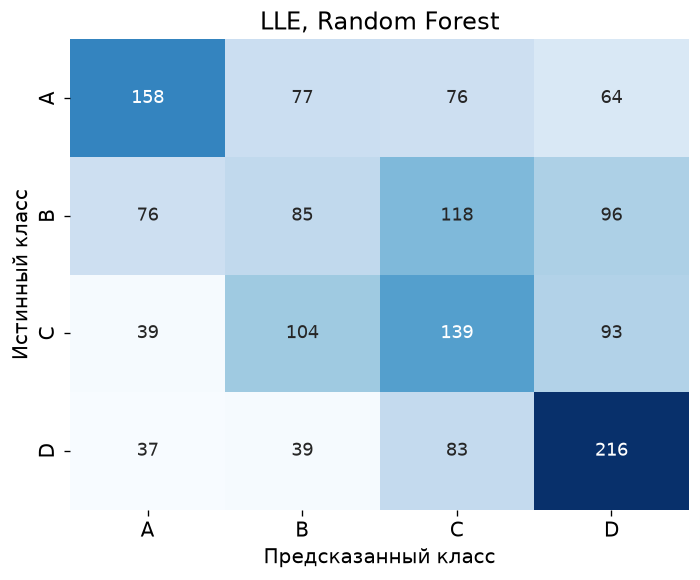

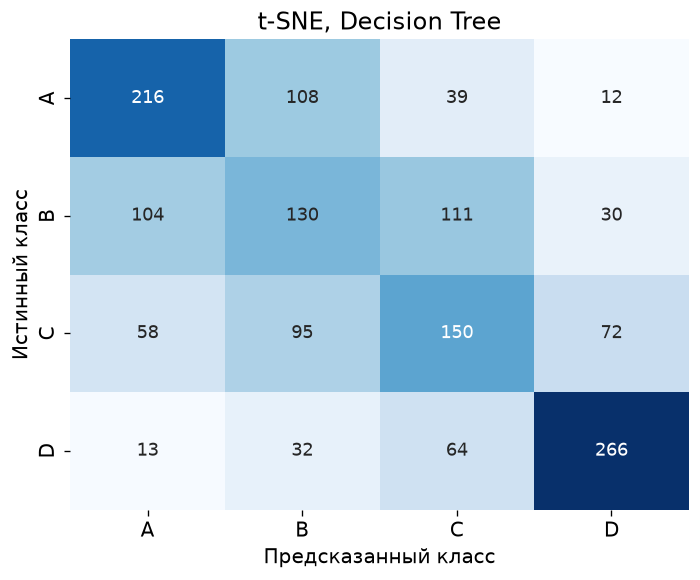

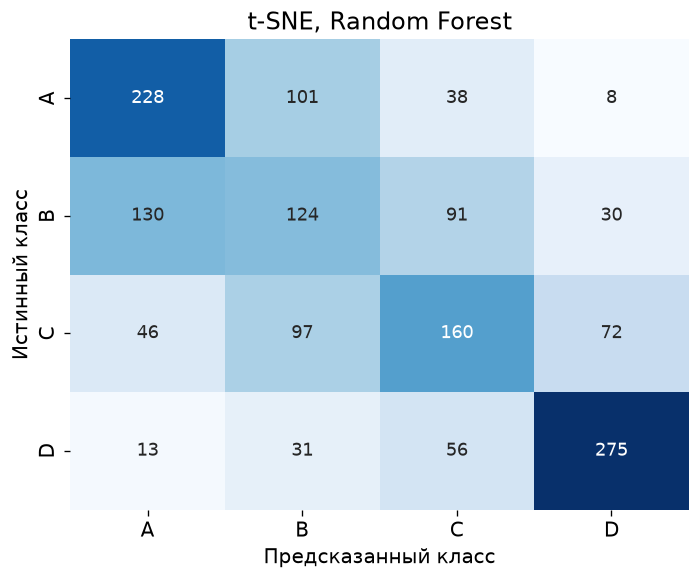

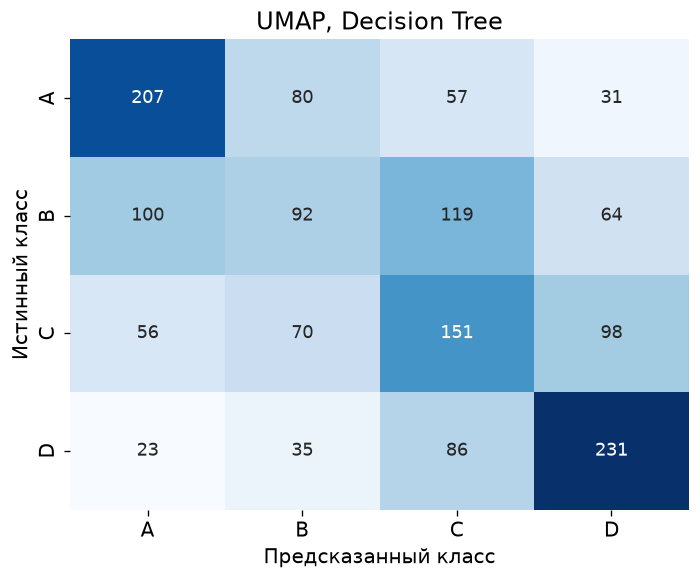

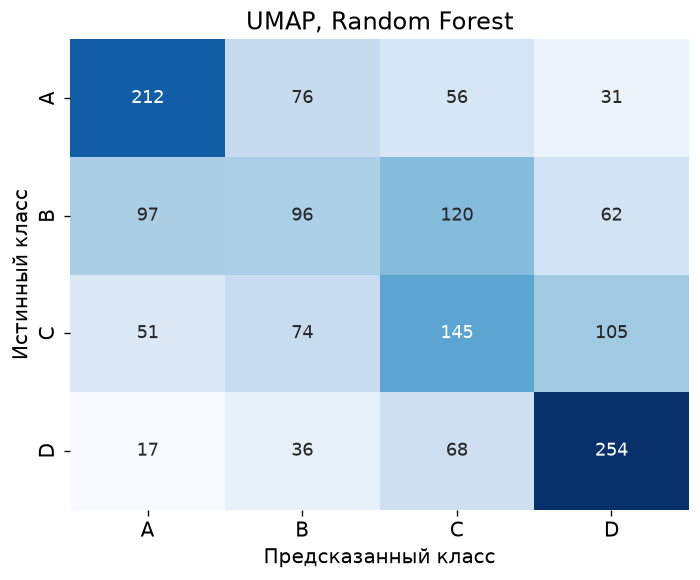

In [30]:
# Матрицы ошибок для всех десяти комбинаций
confusion_rows = []
for method in METHODS:
    slug = METHOD_SLUGS[method]
    for model_name in ["Decision Tree", "Random Forest"]:
        predictions = classification_predictions[(method, model_name)]
        matrix = confusion_matrix(y[test_idx], predictions, labels=list(range(NUMBER_OF_CLASSES)))

        for true_index, true_name in enumerate(CLASS_NAMES):
            for predicted_index, predicted_name in enumerate(CLASS_NAMES):
                confusion_rows.append({
                    "Метод": method,
                    "Модель": model_name,
                    "Истинный класс": true_name,
                    "Предсказанный класс": predicted_name,
                    "Объектов": int(matrix[true_index, predicted_index]),
                })

        figure, axis = plt.subplots(figsize=(6, 5))
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axis,
                    annot_kws={"size": 11})
        # Сетку осей отключаем: на тепловой карте ее линии перечеркивают ячейки
        axis.grid(False)
        axis.set_xlabel("Предсказанный класс")
        axis.set_ylabel("Истинный класс")
        axis.set_title(f"{method}, {model_name}")
        figure.tight_layout()
        file_name = f"lab4-confusion-{slug}-{'dt' if model_name == 'Decision Tree' else 'rf'}.png"
        figure.savefig(FIGURES_DIR / file_name)
        plt.show()

confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(RESULTS_DIR / "lab4-confusion.csv", index=False, encoding="utf-8")

**Результат:** у лучшей модели (t-SNE, Random Forest) классы распознаются неравномерно. F1: A - 0,5758, B - 0,3407, C - 0,4444, D - 0,7237. Крайний класс D определяется лучше всех (Recall 0,7333, Precision 0,7143), класс A - средне (0,6080 и 0,5468), средние B и C - хуже всего.

Матрица ошибок показывает направление путаницы:

- A: 228 верно, 101 назван B, 38 - C, 8 - D;
- B: 124 верно, 130 названы A, 91 - C, 30 - D;
- C: 160 верно, 97 названы B, 46 - A, 72 - D;
- D: 275 верно, 56 названы C, 31 - B, 13 - A.

Почти все ошибки - между соседними классами: B чаще всего путается с A, C - с B и D. Это согласуется с анализом данных: классы A-D - равные страты непрерывной оценки подготовленности, поэтому на границе между ними значения признаков перекрываются. Крайние классы отделяются легче, потому что у них нет соседа с одной стороны.

### 9. Строгая проверка на новых объектах

В этом разделе вложение обучается только на train, а тестовые объекты получают координаты через `transform`. Такой режим возможен только для методов, которые умеют размещать новые точки:

- Isomap - есть `transform`;
- UMAP - есть `transform`;
- MDS, LLE - `transform` отсутствует, метод перестраивает всю карту при добавлении объектов;
- t-SNE - в scikit-learn 1.9.1 метода `transform` нет.

Поэтому строгая таблица содержит только Isomap и UMAP. Сравнивать их с MDS и LLE в этом режиме нельзя: у MDS и LLE такого режима не существует. Разница между основной таблицей и строгой показывает, насколько оптимистичны transductive-оценки.

In [31]:
strict_rows = []

# Isomap: обучаем на train и переносим тест через transform
isomap_strict = Isomap(n_components=2, n_neighbors=isomap_neighbors, n_jobs=-1)
isomap_train_coordinates = isomap_strict.fit_transform(X_train)
isomap_test_coordinates = isomap_strict.transform(X_test)
rows, _, _ = fit_and_evaluate_models(
    "strict", "Isomap", isomap_train_coordinates, y[train_idx], isomap_test_coordinates, y[test_idx]
)
strict_rows.extend(rows)

# UMAP: обучаем на train и переносим тест через transform
umap_strict = umap.UMAP(
    n_components=2,
    n_neighbors=umap_neighbors,
    min_dist=umap_min_dist,
    random_state=SEED,
    n_jobs=1,
).fit(X_train)
umap_train_coordinates = umap_strict.embedding_
umap_test_coordinates = umap_strict.transform(X_test)
rows, _, _ = fit_and_evaluate_models(
    "strict", "UMAP", umap_train_coordinates, y[train_idx], umap_test_coordinates, y[test_idx]
)
strict_rows.extend(rows)

strict_table = pd.DataFrame(strict_rows)
strict_table.to_csv(RESULTS_DIR / "lab4-strict-comparison.csv", index=False, encoding="utf-8")
display(strict_table[strict_table["Модель"] != "Dummy"])

# Сравнение с transductive-оценкой для тех же методов
comparison_rows = []
for method in ["Isomap", "UMAP"]:
    for model_name in ["Decision Tree", "Random Forest"]:
        transductive_accuracy = classification_metrics_table[
            (classification_metrics_table["Оценка"] == "transductive")
            & (classification_metrics_table["Метод"] == method)
            & (classification_metrics_table["Модель"] == model_name)
        ]["Accuracy"].iloc[0]
        strict_accuracy = strict_table[
            (strict_table["Метод"] == method) & (strict_table["Модель"] == model_name)
        ]["Accuracy"].iloc[0]
        comparison_rows.append({
            "Метод": method,
            "Модель": model_name,
            "Accuracy transductive": transductive_accuracy,
            "Accuracy strict": strict_accuracy,
            "Разница": round(float(transductive_accuracy) - float(strict_accuracy), 4),
        })

strict_gap = pd.DataFrame(comparison_rows)
strict_gap.to_csv(RESULTS_DIR / "lab4-strict-gap.csv", index=False, encoding="utf-8")
display(strict_gap)

,Оценка,Метод,Модель,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,Параметры
1,strict,Isomap,Decision Tree,0.3640,0.3587,0.3640,0.3578,0.3587,0.3640,0.3578,"{'max_depth': 7, 'min_samples_leaf': 1}"
2,strict,Isomap,Random Forest,0.3813,0.3745,0.3813,0.3742,0.3745,0.3813,0.3742,"{'max_depth': 10, 'max_features': 'sqrt'}"
4,strict,UMAP,Decision Tree,0.4453,0.4429,0.4453,0.4433,0.4429,0.4453,0.4433,"{'max_depth': 10, 'min_samples_leaf': 10}"
5,strict,UMAP,Random Forest,0.4647,0.4582,0.4647,0.4605,0.4582,0.4647,0.4605,"{'max_depth': 10, 'max_features': 1.0}"


,Метод,Модель,Accuracy transductive,Accuracy strict,Разница
0,Isomap,Decision Tree,0.3653,0.3640,0.0013
1,Isomap,Random Forest,0.3820,0.3813,0.0007
2,UMAP,Decision Tree,0.4540,0.4453,0.0087
3,UMAP,Random Forest,0.4713,0.4647,0.0066


**Результат:** строгая проверка подтверждает transductive-оценки. Для Isomap Accuracy падает с 0,3653 до 0,3640 у Decision Tree (разница 0,0013) и с 0,3820 до 0,3813 у Random Forest (0,0007). Для UMAP - с 0,4540 до 0,4453 (0,0087) и с 0,4713 до 0,4647 (0,0066).

Разница не превышает одного процента, то есть координаты новых объектов, полученные через `transform`, почти не отличаются по качеству от координат, построенных при перестройке всей карты. Для UMAP разрыв немного больше: новым точкам сложнее точно лечь в уже сформированные острова.

Для MDS, LLE и t-SNE строгая проверка невозможна: в scikit-learn 1.9.1 у них нет `transform`. Их transductive-оценки нельзя считать независимыми, но по ним можно сравнивать методы между собой, что и сделано в основной таблице.

## Итоговая оценка на тестовой выборке

Собираем все результаты в одну таблицу: параметры, trustworthiness, stress для MDS, лучшие показатели кластеризации и качество классификаторов. Для Isomap и UMAP дополнительно приводим строгую Accuracy.

Все числа берутся из сохраненных CSV, поэтому таблица, вывод и презентация не разойдутся.

In [32]:
summary_rows = []
for method in METHODS:
    parameters_2d = embedding_params[
        (embedding_params["Метод"] == method) & (embedding_params["Размерность"] == 2)
    ].iloc[0]
    parameters_3d = embedding_params[
        (embedding_params["Метод"] == method) & (embedding_params["Размерность"] == 3)
    ].iloc[0]

    method_clusters = cluster_metrics[cluster_metrics["Метод"] == method]
    best_ari_row = method_clusters.loc[method_clusters["ARI"].idxmax()]
    best_silhouette_row = method_clusters.loc[method_clusters["Silhouette"].idxmax()]

    tree_accuracy = classification_metrics_table[
        (classification_metrics_table["Оценка"] == "transductive")
        & (classification_metrics_table["Метод"] == method)
        & (classification_metrics_table["Модель"] == "Decision Tree")
    ]["Accuracy"].iloc[0]
    forest_accuracy = classification_metrics_table[
        (classification_metrics_table["Оценка"] == "transductive")
        & (classification_metrics_table["Метод"] == method)
        & (classification_metrics_table["Модель"] == "Random Forest")
    ]["Accuracy"].iloc[0]
    tree_f1 = classification_metrics_table[
        (classification_metrics_table["Оценка"] == "transductive")
        & (classification_metrics_table["Метод"] == method)
        & (classification_metrics_table["Модель"] == "Decision Tree")
    ]["F1 macro"].iloc[0]
    forest_f1 = classification_metrics_table[
        (classification_metrics_table["Оценка"] == "transductive")
        & (classification_metrics_table["Метод"] == method)
        & (classification_metrics_table["Модель"] == "Random Forest")
    ]["F1 macro"].iloc[0]

    strict_tree = strict_table[
        (strict_table["Метод"] == method) & (strict_table["Модель"] == "Decision Tree")
    ]
    strict_forest = strict_table[
        (strict_table["Метод"] == method) & (strict_table["Модель"] == "Random Forest")
    ]
    strict_tree_accuracy = float(strict_tree["Accuracy"].iloc[0]) if len(strict_tree) else np.nan
    strict_forest_accuracy = float(strict_forest["Accuracy"].iloc[0]) if len(strict_forest) else np.nan

    summary_rows.append({
        "Метод": method,
        "Параметры 2D": parameters_2d["Параметры"],
        "Trustworthiness 2D": parameters_2d["Trustworthiness"],
        "Trustworthiness 3D": parameters_3d["Trustworthiness"],
        "Stress (MDS)": parameters_2d["Stress"],
        "Лучший K по ARI": int(best_ari_row["K"]),
        "Размерность лучшего ARI": int(best_ari_row["Размерность"]),
        "ARI": best_ari_row["ARI"],
        "NMI": best_ari_row["NMI"],
        "Лучший Silhouette": best_silhouette_row["Silhouette"],
        "DT Accuracy": tree_accuracy,
        "RF Accuracy": forest_accuracy,
        "DT F1 macro": tree_f1,
        "RF F1 macro": forest_f1,
        "DT strict Accuracy": round(strict_tree_accuracy, 4) if not np.isnan(strict_tree_accuracy) else np.nan,
        "RF strict Accuracy": round(strict_forest_accuracy, 4) if not np.isnan(strict_forest_accuracy) else np.nan,
    })

comparison_table = pd.DataFrame(summary_rows)
comparison_table.to_csv(RESULTS_DIR / "lab4-comparison.csv", index=False, encoding="utf-8")
display(comparison_table)

,Метод,Параметры 2D,Trustworthiness 2D,Trustworthiness 3D,Stress (MDS),Лучший K по ARI,Размерность лучшего ARI,ARI,NMI,Лучший Silhouette,DT Accuracy,RF Accuracy,DT F1 macro,RF F1 macro,DT strict Accuracy,RF strict Accuracy
0,MDS,"n_init=1, init=random",0.8843,0.9470,0.2157,6,3,0.0626,0.0840,0.3925,0.3907,0.4080,0.3864,0.3944,NaN,NaN
1,Isomap,n_neighbors=10,0.8803,0.9433,NaN,6,3,0.0368,0.0497,0.4370,0.3653,0.3820,0.3649,0.3506,0.3640,0.3813
2,LLE,"n_neighbors=30, reg=0.001",0.8685,0.9259,NaN,4,3,0.0532,0.0767,0.3856,0.3787,0.3987,0.3709,0.3937,NaN,NaN
3,t-SNE,"perplexity=30, init=pca",0.9923,0.9960,NaN,4,3,0.0368,0.0431,0.4449,0.5080,0.5247,0.5065,0.5211,NaN,NaN
4,UMAP,"n_neighbors=15, min_dist=0.1",0.9419,0.9774,NaN,6,3,0.0408,0.0553,0.5474,0.4540,0.4713,0.4469,0.4625,0.4453,0.4647


**Результат:** итоговая таблица собирает все измерения в одном месте.

| Метод | TW 2D | TW 3D | Stress | ARI max | Silhouette max | DT Accuracy | RF Accuracy | RF strict |
|---|---|---|---|---|---|---|---|---|
| MDS | 0,8843 | 0,9470 | 0,2157 | 0,0626 (K=6, 3D) | 0,3925 | 0,3907 | 0,4080 | - |
| Isomap | 0,8803 | 0,9433 | - | 0,0368 (K=6, 3D) | 0,4370 | 0,3653 | 0,3820 | 0,3813 |
| LLE | 0,8685 | 0,9259 | - | 0,0532 (K=4, 3D) | 0,3856 | 0,3787 | 0,3987 | - |
| t-SNE | 0,9923 | 0,9960 | - | 0,0368 (K=4, 3D) | 0,4449 | 0,5080 | 0,5247 | - |
| UMAP | 0,9419 | 0,9774 | - | 0,0408 (K=6, 3D) | 0,5474 | 0,4540 | 0,4713 | 0,4647 |

Методы упорядочиваются почти одинаково по сохранению соседства, качеству классификации на двумерных координатах и визуальному впечатлению. t-SNE лидирует по trustworthiness и Accuracy, UMAP второй, MDS и Isomap близки, LLE по структуре хуже всех, а по классификации обгоняет Isomap.

Результаты кластеризации не подтверждают разделимость классов ни для одного метода: ARI не выше 0,0626, тогда как Silhouette достигает 0,5474. Это не противоречие: Silhouette измеряет геометрическую компактность без истинных меток, а ARI - совпадение с классами. K-means находит плотные области карты, но эти области не соответствуют уровням подготовленности.

Строгая проверка Isomap и UMAP показывает, что transductive-оценки завышены незначительно: разница не более 0,0087. Значит, основная таблица пригодна для сравнения методов, а вывод о слабой разделимости классов не является артефактом перестройки карты на всех объектах.

## Вывод

Работа выполнена полностью: пять методов снижения размерности (MDS, Isomap, LLE, t-SNE, UMAP) построили двумерные и трехмерные вложения 5 000 объектов Body Performance, для каждого метода сравнены две конфигурации по trustworthiness с допуском 0,005.

Главный результат: классы физической подготовленности A-D визуально не разделяются ни одним методом. t-SNE лучше всех сохраняет локальное соседство (trustworthiness 0,9923 в 2D и 0,9960 в 3D) и дает лучшую классификацию (Random Forest Accuracy 0,5247), UMAP второй (0,9419 и 0,4713), MDS и Isomap близки (0,8843 и 0,8803 по структуре, 0,4080 и 0,3820 по Accuracy), LLE при неудачном k схлопывается (0,5997 при k=10 против 0,8685 при k=30).

Кластеризация K-means при K от 3 до 6 не восстанавливает классы: максимальный ARI 0,0626, хотя Silhouette достигает 0,5474. Кластеры компактны геометрически, но не соответствуют целевой переменной.

Причина слабой разделимости в самих данных: классы A-D - равные страты непрерывной оценки подготовленности, а не природные группы. Признаки связаны с классом умеренно (максимальная корреляция -0,588 у наклона), сильно коррелируют между собой и перекрываются на границах классов. Отсюда ошибки прежде всего между соседними классами, а крайние A и D распознаются лучше.

Практические выводы по методам. MDS и Isomap уместны, когда важно сохранить глобальные расстояния и нужна интерпретируемая карта. LLE чувствителен к числу соседей и при малом k теряет структуру. t-SNE дает самую выразительную визуализацию, но не имеет `transform`, искажает глобальные расстояния и требует перестройки карты для новых объектов. UMAP - лучший компромисс: почти как t-SNE сохраняет локальную структуру, умеет размещать новые объекты через `transform` и дает Accuracy 0,4713 с Random Forest.

Ограничение работы - подвыборка 5 000 объектов. Она вызвана стоимостью матрицы попарных расстояний n x n для MDS, Isomap и LLE: на полном наборе из 13 392 объектов это около 1,4 ГБ памяти и десятки минут на запуск. Подвыборка стратифицированная, поэтому доли классов и выводы не должны измениться качественно.

In [33]:
import sklearn

print("Версии библиотек:")
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("umap-learn", umap.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("seaborn", sns.__version__)

Версии библиотек:
numpy 2.5.4
pandas 3.1.0
scikit-learn 1.9.1
umap-learn 0.5.12
matplotlib 3.11.2
seaborn 0.13.2
